# SPARK Overlay

Load → delta-normalise → select top N cells per condition → plot.

**Key design decisions:**
- Cells with zero signal throughout (true basal, e.g. blank untreated) are kept with `spark_delta=0`
- Cells with zero at frame 0 but rising later (e.g. `0731p2-62` cell 2) use first non-zero frame as reference
- Criteria-1 (basal): hard cap on `peak_delta` to prevent activated cells leaking in
- Criteria-2 (activated): ranked by sustained late-movie signal

In [201]:
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import h5py
import warnings
warnings.filterwarnings('ignore')

sys.path.append('.')
from spark_utils import load_spark_run


In [229]:
# ── load manual curated traces ────────────────────────────────────────────────
manual_dir = '.'
MANUAL_CSV = {
    ('IKK-SPK-novel',  'polyIC'): os.path.join(manual_dir, 'ikk_novel_polyIC_manual.csv'),
    ('TBK-SPK-novel',  'diABZI'): os.path.join(manual_dir, 'tbk1_novel_diABZI_manual.csv'),
}

df_manual = {}
for (reporter, cond), path in MANUAL_CSV.items():
    df_manual[(reporter, cond)] = pd.read_csv(path)
    n = df_manual[(reporter, cond)][['fov','cell_id']].drop_duplicates().shape[0]
    print(f'Loaded {reporter} / {cond}: {n} cells  ({path})')

Loaded IKK-SPK-novel / polyIC: 6 cells  (./ikk_novel_polyIC_manual.csv)
Loaded TBK-SPK-novel / diABZI: 4 cells  (./tbk1_novel_diABZI_manual.csv)


In [202]:
OUTPUT_H5 = '${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5'
SAVE_DIR  = '${SPARK_ACQUISITION_ROOT}/spark_examples/figures'
os.makedirs(SAVE_DIR, exist_ok=True)

# ── reporter name harmonisation (v1 → v2) ────────────────────────────────
REPORTER_ALIAS = {
    'ikkb':       'IKK-SPK-1',
    'tbk1':       'TBK-SPK-1',
    'tbk1-novel': 'TBK-SPK-novel',
    'ikkb-novel': 'IKK-SPK-novel',
}

# ── condition remapping ───────────────────────────────────────────────────
CONDITION_REMAP = {
    'blank+GSK8612': 'GSK8612',
    'GSK-8612':      'GSK8612',
}

# ── selection criteria ────────────────────────────────────────────────────
# 1 = basal: lowest peak delta, smoothest
# 2 = activated: highest sustained response, smoothest
SELECTION_CRITERIA = {
    ('IKK-SPK-1',    'BMS-345541'): 1,
    ('IKK-SPK-1',    'GSK8612'):    1,
    ('IKK-SPK-1',    'TNFa'):       2,
    ('IKK-SPK-1',    'blank'):      1,
    ('IKK-SPK-1',    'diABZI'):     2,
    ('IKK-SPK-1',    'polyIC'):     2,
    ('IKK-SPK-1-TA', 'TNFa'):       1,
    ('IKK-SPK-1-TA', 'blank'):      1,
    ('IKK-SPK-1-TA', 'diABZI'):     1,
    ('IKK-SPK-novel','BMS-345541'): 1,
    ('IKK-SPK-novel','blank'):      1,
    ('IKK-SPK-novel','TNFa'):       2,
    ('IKK-SPK-novel','diABZI'):     2,
    ('IKK-SPK-novel','polyIC'):     2,
    ('TBK-SPK-1',    'blank'):      1,
    ('TBK-SPK-1',    'GSK8612'):    1,
    ('TBK-SPK-1',    'diABZI'):     2,
    ('TBK-SPK-1',    'polyIC'):     2,
    ('TBK-SPK-1-TA', 'TNFa'):       1,
    ('TBK-SPK-1-TA', 'diABZI'):     1,
    ('TBK-SPK-1-TA', 'blank'):      1,
    ('TBK-SPK-novel','diABZI'):     2,
    ('TBK-SPK-novel','polyIC'):     2,
    ('TBK-SPK-novel','blank'):      1,
    ('TBK-SPK-novel','GSK8612'):    1,
    ('TBK-SPK-novel-TA','diABZI'):    1,
    ('TBK-SPK-novel-TA','polyIC'):    1,
    ('TBK-SPK-novel-TA','blank'):    1
}

# ── condition display ─────────────────────────────────────────────────────
CONDITION_ORDER = ['blank', 'GSK8612', 'BMS-345541',
                   'polyIC', 'diABZI', 'TNFa']
CONDITION_COLORS = {
    'blank':      '#888888',
    'GSK8612':    '#aaaaaa',
    'BMS-345541': '#9C27B0',
    'polyIC':     '#2196F3',
    'diABZI':     '#F44336',
    'TNFa':       '#FF9800',
}
DEFAULT_COLOR = '#333333'


ACTIVATION_THRESH  = 0.02   # min peak delta for criteria-2
# BASAL_PEAK_CAP     = 0.05   # max peak delta for criteria-1
BASAL_PEAK_CAP     = 0.05   # max peak delta for criteria-1
BASELINE_SPARK_THRESH = 0.2 # drop cells pre-activated at frame 0
MIN_FRAME_FRAC     = 0.85   # min fraction of frames present
SMOOTH_SPIKE_Z     = 2.5
SMOOTH_WINDOW      = 5
SAVGOL_WINDOW      = 7
SAVGOL_POLY        = 2

with h5py.File(OUTPUT_H5, 'r') as hf:
    run_keys = list(hf.keys())
print(f'Runs available: {len(run_keys)}')


Runs available: 200


In [203]:
SELECTION_CRITERIA.keys()

dict_keys([('IKK-SPK-1', 'BMS-345541'), ('IKK-SPK-1', 'GSK8612'), ('IKK-SPK-1', 'TNFa'), ('IKK-SPK-1', 'blank'), ('IKK-SPK-1', 'diABZI'), ('IKK-SPK-1', 'polyIC'), ('IKK-SPK-1-TA', 'TNFa'), ('IKK-SPK-1-TA', 'blank'), ('IKK-SPK-1-TA', 'diABZI'), ('IKK-SPK-novel', 'BMS-345541'), ('IKK-SPK-novel', 'blank'), ('IKK-SPK-novel', 'TNFa'), ('IKK-SPK-novel', 'diABZI'), ('IKK-SPK-novel', 'polyIC'), ('TBK-SPK-1', 'blank'), ('TBK-SPK-1', 'GSK8612'), ('TBK-SPK-1', 'diABZI'), ('TBK-SPK-1', 'polyIC'), ('TBK-SPK-1-TA', 'TNFa'), ('TBK-SPK-1-TA', 'diABZI'), ('TBK-SPK-1-TA', 'blank'), ('TBK-SPK-novel', 'diABZI'), ('TBK-SPK-novel', 'polyIC'), ('TBK-SPK-novel', 'blank'), ('TBK-SPK-novel', 'GSK8612'), ('TBK-SPK-novel-TA', 'diABZI'), ('TBK-SPK-novel-TA', 'polyIC'), ('TBK-SPK-novel-TA', 'blank')])

In [204]:
# ── load all runs ─────────────────────────────────────────────────────────
dfs = []
for rk in run_keys:
    meta, df, _, _ = load_spark_run(OUTPUT_H5, rk)
    raw_reporter    = meta.get('reporter', rk)
    df['reporter']  = REPORTER_ALIAS.get(raw_reporter, raw_reporter)
    df['condition'] = meta.get('condition', 'unknown')
    df['run_key']   = rk
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)
df_all['condition'] = df_all['condition'].replace(CONDITION_REMAP)

# drop any pre-computed normalisation columns saved in HDF5 —
# these will be recomputed fresh by cell_norm
for _col in ['frame0_signal', 'spark_delta', 'spark_norm',
             'spark_norm_ctrl', 'spark_f0norm']:
    if _col in df_all.columns:
        df_all.drop(columns=[_col], inplace=True)
        print(f'Dropped stale column from HDF5: {_col}')

print(f'Loaded: {len(df_all)} rows | '
      f'{df_all.run_key.nunique()} runs | '
      f'{df_all[["run_key","cell_id"]].drop_duplicates().shape[0]} cells')

Dropped stale column from HDF5: spark_norm
Dropped stale column from HDF5: spark_norm_ctrl
Loaded: 93702 rows | 200 runs | 1722 cells


In [205]:
# ── fix time_min for 20250126 and 20250130 plate1 runs ───────────────────────
# These 49-frame runs were acquired at 5 min/frame but processed with
# minutes_per_frame=4.0, giving max time_min=192 min instead of 240 min.
# Correct: frame * 5.0  →  frame 0=0 min, frame 48=240 min.

RUNS_5MIN = [rk for rk in df_all['run_key'].unique()
             if rk.startswith('20250126_plate1')
             or rk.startswith('20250130_plate1')]

mask_5min = df_all['run_key'].isin(RUNS_5MIN)
df_all.loc[mask_5min, 'time_min'] = df_all.loc[mask_5min, 'frame'] * 5.0

print(f'Frame-rate fix applied to {len(RUNS_5MIN)} runs:')
for rk in sorted(RUNS_5MIN):
    n  = int(df_all[df_all['run_key'] == rk]['frame'].max()) + 1
    mx = df_all[df_all['run_key'] == rk]['time_min'].max()
    print(f'  {rk}: {n} frames → max={mx:.1f} min')


Frame-rate fix applied to 67 runs:
  20250126_plate1_xy03: 49 frames → max=240.0 min
  20250126_plate1_xy05: 49 frames → max=240.0 min
  20250126_plate1_xy11: 49 frames → max=240.0 min
  20250126_plate1_xy14: 49 frames → max=240.0 min
  20250126_plate1_xy15: 49 frames → max=240.0 min
  20250126_plate1_xy19: 49 frames → max=240.0 min
  20250126_plate1_xy21: 49 frames → max=240.0 min
  20250126_plate1_xy22: 49 frames → max=240.0 min
  20250126_plate1_xy23: 49 frames → max=240.0 min
  20250126_plate1_xy24: 49 frames → max=240.0 min
  20250126_plate1_xy25: 49 frames → max=240.0 min
  20250126_plate1_xy26: 49 frames → max=240.0 min
  20250126_plate1_xy27: 49 frames → max=240.0 min
  20250126_plate1_xy28: 49 frames → max=240.0 min
  20250126_plate1_xy29: 49 frames → max=240.0 min
  20250126_plate1_xy32: 49 frames → max=240.0 min
  20250126_plate1_xy33: 49 frames → max=240.0 min
  20250126_plate1_xy34: 49 frames → max=240.0 min
  20250126_plate1_xy37: 49 frames → max=240.0 min
  20250126_plat

In [206]:
# run this BEFORE cell_norm
for _col in ['frame0_signal', 'spark_delta', 'spark_smoothed']:
    if _col in df_all.columns:
        df_all.drop(columns=[_col], inplace=True)
print('Dropped. Columns now:', [c for c in df_all.columns if 'spark' in c or 'frame0' in c])

Dropped. Columns now: ['spark_signal']


In [207]:
def get_baseline(grp):
    f0_rows = grp[grp['frame'] == 0]['spark_signal'].values
    f0_val  = float(f0_rows[0]) if len(f0_rows) > 0 else 0.0

    grp = grp.copy()
    if f0_val >= 0:
        # normal case: cell has signal at frame 0 — use as reference
        grp['frame0_signal'] = f0_val
    else:
        nonzero = grp[grp['spark_signal'] > 0]
        if len(nonzero) == 0:
            # truly silent throughout
            grp['frame0_signal'] = 0.0
        else:
            # silent at frame 0 but activates later
            # use first non-zero frame as reference
            grp['frame0_signal'] = float(nonzero['spark_signal'].iloc[0])
    return grp

df_all = (df_all.groupby(['run_key','cell_id'], group_keys=False)
          .apply(get_baseline))
df_all['spark_delta'] = df_all['spark_signal'] - df_all['frame0_signal']
# ── sustained filter ─────────────────────────────────────────────────────
# Use max frame index + 1 per run so each run is judged against its own
# expected total: 4min/frame runs → 61 frames, 5min/frame runs → 49 frames.
RUN_EXPECTED_FRAMES = {
    rk: int(df_all[df_all['run_key'] == rk]['frame'].max()) + 1
    for rk in df_all['run_key'].unique()
}
n_frames_per_run = pd.Series(RUN_EXPECTED_FRAMES)

valid_counts = (df_all.dropna(subset=['spark_signal'])
                .groupby(['run_key','cell_id'])['frame'].nunique()
                .reset_index().rename(columns={'frame':'n_valid'}))
valid_counts['n_total']    = valid_counts['run_key'].map(n_frames_per_run)
valid_counts['frame_frac'] = valid_counts['n_valid'] / valid_counts['n_total']
sustained = valid_counts[valid_counts['frame_frac'] >= MIN_FRAME_FRAC]

df_all = (df_all
          .merge(sustained[['run_key','cell_id']], on=['run_key','cell_id'])
          .query('frame0_signal.notna()')
          .copy())

n_cells = df_all[['run_key','cell_id']].drop_duplicates().shape[0]
print(f'After sustained filter: {n_cells} cells')

# ── spot-checks ──────────────────────────────────────────────────────────
for rk, cid, label in [
    ('0731p2-62',         2, 'case B activated from zero'),
    ('240731p2-50',       1, 'case A truly silent basal'),
    ('240815_plate3_xy02',1, 'previously negative delta'),
    ('240815_plate3_xy02',3, 'previously negative delta'),
]:
    grp = df_all[(df_all['run_key']==rk) & (df_all['cell_id']==cid)]
    if len(grp) == 0:
        print(f'{rk} cell {cid}: NOT in df_all')
        continue
    dmin = grp['spark_delta'].min()
    dmax = grp['spark_delta'].max()
    f0   = grp['frame0_signal'].iloc[0]
    ok   = dmin >= -1e-9
    print(f'{rk} cell {cid} ({label}): '
          f'f0={f0:.5f}  delta=[{dmin:.5f}, {dmax:.5f}]  '
          f'[{"OK" if ok else "STILL NEGATIVE"}]')

After sustained filter: 1374 cells
0731p2-62 cell 2 (case B activated from zero): f0=0.00000  delta=[0.00000, 0.14511]  [OK]
240731p2-50 cell 1 (case A truly silent basal): f0=0.00000  delta=[0.00000, 0.00000]  [OK]
240815_plate3_xy02 cell 1 (previously negative delta): f0=0.00000  delta=[0.00000, 0.03202]  [OK]
240815_plate3_xy02 cell 3 (previously negative delta): f0=0.00000  delta=[0.00000, 0.00792]  [OK]


In [208]:
# ── smooth each cell trace ───────────────────────────────────────────────
def smooth_trace(trace, spike_z=SMOOTH_SPIKE_Z, window=SMOOTH_WINDOW):
    """Replace isolated spikes with rolling median; leave trend intact."""
    s           = pd.Series(trace.copy())
    rolling_med = s.rolling(window, center=True, min_periods=1).median()
    residual    = s - rolling_med
    std         = residual.std()
    if std > 0:
        z = (residual - residual.mean()) / std
        s[z.abs() > spike_z] = rolling_med[z.abs() > spike_z]
    return s.values

smoothed_rows = []
for (rk, cid), grp in df_all.groupby(['run_key','cell_id']):
    grp = grp.sort_values('frame').copy()
    grp['spark_smoothed'] = smooth_trace(grp['spark_delta'].values)
    smoothed_rows.append(grp)

df_all = pd.concat(smoothed_rows, ignore_index=True)
print(f'Smoothing done — '
      f'{df_all[["run_key","cell_id"]].drop_duplicates().shape[0]} cells')


Smoothing done — 1374 cells


In [209]:
# ── filter oscillating cells ──────────────────────────────────────────────────
# Remove cells whose smoothed trace flips direction too frequently
# at large magnitude — these are noisy/artefactual not biological dynamics.

def has_local_alternating(trace, window=10, min_alt_frac=0.7, min_step=0.005):
    diffs = np.diff(trace)
    for i in range(len(diffs) - window + 1):
        window_diffs = diffs[i:i+window]
        sign_flips = (np.diff(np.sign(window_diffs)) != 0).sum()
        flip_frac  = sign_flips / (len(window_diffs) - 1)
        mean_step  = np.abs(window_diffs).mean()
        if flip_frac >= min_alt_frac and mean_step >= min_step:
            return True
    return False


def has_spike_cliff(trace, low=0.001, high=0.05):
    for i in range(len(trace) - 1):
        a, b = trace[i], trace[i + 1]
        if a < low  and b > high: return True
        if a > high and b < low:  return True
    return False


LOW_THRESH            = 0.001
HIGH_THRESH           = 0.05
LOCAL_WINDOW          = 10
LOCAL_ALT_FRAC        = 0.7
LOCAL_MIN_STEP        = 0.005
MAX_DIRECTION_FLIP_FRAC  = 0.55
MAX_LARGE_STEP_FRAC      = 0.30
LARGE_STEP_FRAC_OF_RANGE = 0.15

osc_flags = []
for (rk, cid), grp in df_all.groupby(['run_key', 'cell_id']):
    trace = grp.sort_values('frame')['spark_smoothed'].values
    if len(trace) < 4:
        osc_flags.append({'run_key': rk, 'cell_id': cid, 'oscillating': False})
        continue

    diffs     = np.diff(trace)
    sig_range = trace.max() - trace.min()

    sign_changes    = np.diff(np.sign(diffs))
    flip_frac       = (sign_changes != 0).sum() / len(sign_changes)

    if sig_range > 1e-9:
        large_steps     = np.abs(diffs) > (LARGE_STEP_FRAC_OF_RANGE * sig_range)
        large_step_frac = large_steps.sum() / len(diffs)
    else:
        large_step_frac = 0.0

    local_alt   = has_local_alternating(trace, window=LOCAL_WINDOW,
                                        min_alt_frac=LOCAL_ALT_FRAC,
                                        min_step=LOCAL_MIN_STEP)
    spike_cliff = has_spike_cliff(trace, low=LOW_THRESH, high=HIGH_THRESH)

    is_osc = (
        (flip_frac > MAX_DIRECTION_FLIP_FRAC and
         large_step_frac > MAX_LARGE_STEP_FRAC)
        or local_alt
        or spike_cliff
    )

    osc_flags.append({
        'run_key':         rk,
        'cell_id':         cid,
        'flip_frac':       float(flip_frac),
        'large_step_frac': float(large_step_frac),
        'sig_range':       float(sig_range),
        'spike_cliff':     bool(spike_cliff),
        'oscillating':     bool(is_osc),
    })

df_osc  = pd.DataFrame(osc_flags)
n_osc   = df_osc['oscillating'].sum()
n_total = len(df_osc)
print(f'Oscillating cells flagged: {n_osc} / {n_total} ({100*n_osc/n_total:.0f}%)')
print(f'  of which spike/cliff:    {df_osc["spike_cliff"].sum()}')

print('\nTop oscillators:')
print(df_osc[df_osc['oscillating']]
      .sort_values('flip_frac', ascending=False)
      [['run_key','cell_id','flip_frac','large_step_frac','sig_range','spike_cliff']]
      .head(20).to_string(index=False))

clean_cells = df_osc[~df_osc['oscillating']][['run_key','cell_id']]
df_all      = df_all.merge(clean_cells, on=['run_key','cell_id'])
n_after     = df_all[['run_key','cell_id']].drop_duplicates().shape[0]
print(f'\nAfter oscillation filter: {n_after} / {n_total} cells retained')


Oscillating cells flagged: 241 / 1374 (18%)
  of which spike/cliff:    87

Top oscillators:
           run_key  cell_id  flip_frac  large_step_frac  sig_range  spike_cliff
           0822-28        9   1.000000         1.000000   0.053189        False
           0822-02        4   1.000000         1.000000   0.107964        False
           0822-20        7   1.000000         0.923077   0.054441        False
           0822-18        2   1.000000         0.903846   0.023568        False
         240822-08        7   1.000000         0.750000   0.027990        False
           0822-13       19   0.980392         0.826923   0.108026        False
           0822-28        2   0.960784         0.865385   0.078263        False
           0822-20       15   0.921569         0.884615   0.045553        False
           0822-20       14   0.921569         0.788462   0.046476        False
           0822-02        9   0.901961         0.884615   0.048644        False
           0822-13        9 

In [210]:
# ── interpolate single-frame spikes in spark_smoothed ────────────────────────
SPIKE_DELTA = 0.04

def interpolate_spikes(trace, spike_delta=SPIKE_DELTA):
    trace = trace.copy().astype(float)
    n     = len(trace)
    if n < 3:
        return trace
    diffs      = np.abs(np.diff(trace))
    spike_mask = np.zeros(n, dtype=bool)
    for i in range(1, n - 1):
        if diffs[i - 1] > spike_delta and diffs[i] > spike_delta:
            spike_mask[i] = True
    if not spike_mask.any():
        return trace
    in_seg    = False
    seg_start = None
    for i in range(n):
        if spike_mask[i] and not in_seg:
            seg_start = i
            in_seg    = True
        if (not spike_mask[i] or i == n - 1) and in_seg:
            seg_end = i - 1 if not spike_mask[i] else i
            left    = seg_start - 1
            right   = seg_end   + 1
            if left >= 0 and right < n:
                trace[left:right + 1] = np.linspace(
                    trace[left], trace[right], right - left + 1)
            in_seg = False
    return trace

rows        = []
n_corrected = 0
for (rk, cid), grp in df_all.groupby(['run_key', 'cell_id']):
    grp   = grp.sort_values('frame').copy()
    orig  = grp['spark_smoothed'].values
    fixed = interpolate_spikes(orig, spike_delta=SPIKE_DELTA)
    if not np.allclose(orig, fixed):
        n_corrected += 1
    grp['spark_smoothed'] = fixed
    rows.append(grp)

df_all  = pd.concat(rows).sort_values(
    ['run_key','cell_id','frame']).reset_index(drop=True)
n_cells = df_all[['run_key','cell_id']].drop_duplicates().shape[0]
print(f'Spike interpolation (|Δ| > {SPIKE_DELTA}):')
print(f'  Cells corrected: {n_corrected} / {n_cells}')


Spike interpolation (|Δ| > 0.04):
  Cells corrected: 1 / 1133


In [211]:
# ── diagnostic: find actual step sizes in spark_smoothed ─────────────────────
# Run this after cell_smooth and oscillation filter to find the right threshold.

import numpy as np
import pandas as pd

step_stats = []
for (rk, cid), grp in df_all.groupby(['run_key', 'cell_id']):
    trace = grp.sort_values('frame')['spark_smoothed'].values
    if len(trace) < 2:
        continue
    diffs = np.abs(np.diff(trace))
    step_stats.append({
        'run_key':   rk,
        'cell_id':   cid,
        'reporter':  grp['reporter'].iloc[0],
        'condition': grp['condition'].iloc[0],
        'max_step':  float(diffs.max()),
        'p95_step':  float(np.percentile(diffs, 95)),
        'p99_step':  float(np.percentile(diffs, 99)),
        'mean_step': float(diffs.mean()),
    })

df_steps = pd.DataFrame(step_stats).sort_values('max_step', ascending=False)

print('Distribution of max single-frame steps in spark_smoothed:')
print(f'  global max:  {df_steps["max_step"].max():.5f}')
print(f'  p99:         {df_steps["max_step"].quantile(0.99):.5f}')
print(f'  p95:         {df_steps["max_step"].quantile(0.95):.5f}')
print(f'  p90:         {df_steps["max_step"].quantile(0.90):.5f}')
print(f'  median:      {df_steps["max_step"].median():.5f}')
print()

# how many cells would be affected at various thresholds
for thresh in [0.04, 0.03, 0.02, 0.015, 0.01, 0.005]:
    n = (df_steps['max_step'] > thresh).sum()
    print(f'  |Δ| > {thresh:.3f}: {n} / {len(df_steps)} cells '
          f'({100*n/len(df_steps):.1f}%) have at least one step above threshold')

print()
print('Top 20 cells with largest single-frame steps:')
print(df_steps[['run_key','cell_id','reporter','condition',
                'max_step','p99_step','mean_step']]
      .head(20).to_string(index=False))

# also check specifically for TBK-SPK-1 / diABZI
print()
print('TBK-SPK-1 / diABZI step sizes:')
sub = df_steps[(df_steps['reporter']=='TBK-SPK-1') &
               (df_steps['condition']=='diABZI')]
print(sub[['run_key','cell_id','max_step','p99_step','mean_step']]
      .sort_values('max_step', ascending=False).to_string(index=False))

Distribution of max single-frame steps in spark_smoothed:
  global max:  0.12745
  p99:         0.05543
  p95:         0.03152
  p90:         0.01885
  median:      0.00000

  |Δ| > 0.040: 32 / 1133 cells (2.8%) have at least one step above threshold
  |Δ| > 0.030: 64 / 1133 cells (5.6%) have at least one step above threshold
  |Δ| > 0.020: 110 / 1133 cells (9.7%) have at least one step above threshold
  |Δ| > 0.015: 148 / 1133 cells (13.1%) have at least one step above threshold
  |Δ| > 0.010: 192 / 1133 cells (16.9%) have at least one step above threshold
  |Δ| > 0.005: 262 / 1133 cells (23.1%) have at least one step above threshold

Top 20 cells with largest single-frame steps:
             run_key  cell_id      reporter  condition  max_step  p99_step  mean_step
  240815_plate4_xy33        7 IKK-SPK-novel    GSK8612  0.127450  0.127450   0.005441
             0822-18       10 IKK-SPK-novel      blank  0.115429  0.069194   0.003173
  240731_plate2_xy06       18     IKK-SPK-1    GSK86

In [212]:
# ── interpolate segmentation dropout gaps in spark_smoothed ──────────────────
# Handles two dropout patterns:
#
#   1. MISSING ROWS: frames entirely absent from df_all (cell not tracked).
#      Detected by comparing present frames against the full frame range.
#      Fixed by inserting rows with interpolated spark_smoothed values.
#
#   2. CLAMPED RUNS: consecutive frames with an identical non-zero value
#      (the tracker kept the cell but signal was clipped/stuck at a floor).
#      Detected as runs of the same repeated value flanked by different values.
#      Fixed by linear interpolation across the clamped segment.
#
# Place this cell AFTER cell_smooth and BEFORE cell_select.

MAX_GAP_FRAMES   = 12   # interpolate missing-row gaps up to this long
MAX_CLAMP_FRAMES = 15   # interpolate clamped runs up to this long
CLAMP_REPEAT_MIN = 4    # minimum consecutive identical frames to flag as clamp

def full_frame_range(df):
    """Return the set of all frames that exist for any cell in a run."""
    return set(df['frame'].unique())

def interpolate_missing_rows(grp, all_frames, max_gap=MAX_GAP_FRAMES):
    """
    Insert rows for frames where the cell was not tracked.
    Interpolates spark_smoothed; copies metadata from nearest neighbour.
    """
    present = set(grp['frame'].values)
    missing = sorted(all_frames - present)
    if not missing:
        return grp

    # find contiguous missing segments
    segments = []
    seg = [missing[0]]
    for f in missing[1:]:
        if f == seg[-1] + 1:
            seg.append(f)
        else:
            segments.append(seg)
            seg = [f]
    segments.append(seg)

    new_rows = []
    trace_dict = dict(zip(grp['frame'], grp['spark_smoothed']))
    template   = grp.iloc[0].to_dict()   # for metadata copying

    for seg in segments:
        gap_len = len(seg)
        left_f  = seg[0]  - 1
        right_f = seg[-1] + 1
        left_v  = trace_dict.get(left_f)
        right_v = trace_dict.get(right_f)

        if (gap_len <= max_gap and
                left_v is not None and right_v is not None):
            interp_vals = np.linspace(left_v, right_v, gap_len + 2)[1:-1]
            for f, v in zip(seg, interp_vals):
                row = template.copy()
                row['frame']          = f
                row['spark_smoothed'] = v
                row['spark_signal']   = np.nan   # no raw signal for missing frame
                row['spark_delta']    = v
                # interpolate time_min from neighbours
                row['time_min'] = (left_f + (f - left_f) *
                                   (grp[grp['frame']==right_f]['time_min'].values[0] -
                                    grp[grp['frame']==left_f ]['time_min'].values[0]) /
                                   (right_f - left_f)
                                   if right_f in set(grp['frame']) and
                                      left_f  in set(grp['frame'])
                                   else np.nan)
                new_rows.append(row)

    if new_rows:
        grp = pd.concat([grp, pd.DataFrame(new_rows)],
                        ignore_index=True).sort_values('frame')
    return grp


def interpolate_clamped_runs(trace, max_clamp=MAX_CLAMP_FRAMES,
                              min_repeat=CLAMP_REPEAT_MIN):
    """
    Replace runs of >=min_repeat identical consecutive values (clamped signal)
    with linear interpolation between the flanking different values.
    """
    trace = trace.copy().astype(float)
    n     = len(trace)
    if n < min_repeat + 2:
        return trace

    i = 0
    while i < n:
        # find run of identical values starting at i
        j = i + 1
        while j < n and trace[j] == trace[i]:
            j += 1
        run_len = j - i   # frames i..j-1 all have same value

        if run_len >= min_repeat:
            left  = i - 1
            right = j      # first frame after the run
            if (left >= 0 and right < n and
                    trace[left] != trace[i] and
                    trace[right] != trace[i] and
                    run_len <= max_clamp):
                n_pts  = right - left + 1
                interp = np.linspace(trace[left], trace[right], n_pts)
                trace[left:right + 1] = interp
        i = j

    return trace


# ── apply both fixes ─────────────────────────────────────────────────────────
rows           = []
n_missing_fixed = 0
n_clamp_fixed   = 0
fix_log         = []

for rk, run_grp in df_all.groupby('run_key'):
    all_frames = full_frame_range(run_grp)

    for cid, grp in run_grp.groupby('cell_id'):
        grp  = grp.sort_values('frame').copy()
        orig = grp['spark_smoothed'].values

        # fix 1: missing rows
        grp_fixed = interpolate_missing_rows(grp, all_frames,
                                             max_gap=MAX_GAP_FRAMES)
        n_inserted = len(grp_fixed) - len(grp)

        # fix 2: clamped runs
        trace_after = interpolate_clamped_runs(
            grp_fixed.sort_values('frame')['spark_smoothed'].values,
            max_clamp=MAX_CLAMP_FRAMES,
            min_repeat=CLAMP_REPEAT_MIN)
        grp_fixed = grp_fixed.sort_values('frame').copy()
        grp_fixed['spark_smoothed'] = trace_after
        n_clamp = int(not np.allclose(
            grp_fixed['spark_smoothed'].values,
            interpolate_missing_rows(grp, all_frames,
                max_gap=MAX_GAP_FRAMES
            ).sort_values('frame')['spark_smoothed'].values))

        if n_inserted > 0 or n_clamp:
            fix_log.append({
                'run_key':    rk,
                'cell_id':    cid,
                'reporter':   grp['reporter'].iloc[0],
                'condition':  grp['condition'].iloc[0],
                'rows_inserted': n_inserted,
                'clamp_fixed':   bool(n_clamp),
            })
            if n_inserted > 0: n_missing_fixed += 1
            if n_clamp:        n_clamp_fixed   += 1

        rows.append(grp_fixed)

df_all  = pd.concat(rows).sort_values(
    ['run_key', 'cell_id', 'frame']).reset_index(drop=True)
n_cells = df_all[['run_key', 'cell_id']].drop_duplicates().shape[0]

print(f'Gap interpolation results:')
print(f'  Missing-row gaps filled : {n_missing_fixed} cells')
print(f'  Clamped runs fixed      : {n_clamp_fixed} cells')

if fix_log:
    df_fix = pd.DataFrame(fix_log)
    print(f'\n  All fixed cells:')
    print(df_fix.to_string(index=False))

    # spot-check xy38
    for cid in [7, 23]:
        row = df_fix[(df_fix['run_key'] == '20250126_plate1_xy38') &
                     (df_fix['cell_id'] == cid)]
        if len(row):
            r = row.iloc[0]
            print(f'\n  xy38 cell {cid}: '
                  f'rows_inserted={r["rows_inserted"]}  '
                  f'clamp_fixed={r["clamp_fixed"]}')
        else:
            print(f'\n  xy38 cell {cid}: no fix applied')

Gap interpolation results:
  Missing-row gaps filled : 62 cells
  Clamped runs fixed      : 60 cells

  All fixed cells:
             run_key  cell_id      reporter  condition  rows_inserted  clamp_fixed
           0731p3-60        3 TBK-SPK-novel     polyIC              0         True
           0731p3-65        1 TBK-SPK-novel     diABZI              5        False
           0731p3-65        2 TBK-SPK-novel     diABZI              0         True
           0731p3-65        9 TBK-SPK-novel     diABZI              0         True
             0822-13       40     IKK-SPK-1       TNFa              5        False
             0822-28       11 IKK-SPK-novel       TNFa              5        False
20250126_plate1_xy11       11     TBK-SPK-1     diABZI              6        False
20250126_plate1_xy11       21     TBK-SPK-1     diABZI              7        False
20250126_plate1_xy14        8     TBK-SPK-1     diABZI              0         True
20250126_plate1_xy15       30     TBK-SPK-1     d

In [282]:
# # ── rationalize basal cap and activation threshold ────────────────────────────
# # Computes the empirical distribution of peak_delta separately for conditions
# # labelled basal (criteria=1) and activated (criteria=2) to check whether
# # BASAL_PEAK_CAP=0.05 and ACTIVATION_THRESH=0.01 sit at natural breakpoints.

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# # ── panel 1: peak_delta distribution for all basal conditions ─────────────────
# ax = axes[0]
# basal_pool = df_stats[df_stats['criteria'] == 1]['peak_delta'].values
# ax.hist(basal_pool, bins=80, color='#888888', alpha=0.7, density=True)
# ax.axvline(0.05, color='red',   lw=2, ls='--', label=f'BASAL_PEAK_CAP=0.05')
# ax.axvline(np.percentile(basal_pool, 95), color='orange', lw=1.5, ls=':',
#            label=f'p95={np.percentile(basal_pool,95):.4f}')
# # ax.axvline(np.percentile(basal_pool, 99), color='purple', lw=1.5, ls=':',
# #            label=f'p99={np.percentile(basal_pool,99):.4f}')
# ax.set_xlabel('peak_delta', fontsize=10)
# ax.set_ylabel('density', fontsize=10)
# ax.set_title('Basal conditions — peak_delta distribution', fontsize=10)
# ax.legend(fontsize=8, frameon=False)
# ax.spines[['top','right']].set_visible(False)

# # stats
# print('=== BASAL PEAK_DELTA STATISTICS ===')
# print(f'  n cells        : {len(basal_pool)}')
# print(f'  median         : {np.median(basal_pool):.5f}')
# print(f'  mean           : {basal_pool.mean():.5f}')
# print(f'  p75            : {np.percentile(basal_pool, 75):.5f}')
# print(f'  p90            : {np.percentile(basal_pool, 90):.5f}')
# print(f'  p95            : {np.percentile(basal_pool, 95):.5f}')
# print(f'  p99            : {np.percentile(basal_pool, 99):.5f}')
# print(f'  max            : {basal_pool.max():.5f}')
# print(f'  % above 0.05   : {(basal_pool > 0.05).mean()*100:.1f}%  '
#       f'({(basal_pool > 0.05).sum()} cells excluded)')
# print(f'  % above 0.03   : {(basal_pool > 0.03).mean()*100:.1f}%')
# print(f'  % above 0.02   : {(basal_pool > 0.02).mean()*100:.1f}%')
# print()

# # per reporter breakdown
# print('  Per-reporter basal peak_delta p95:')
# for rep, grp in df_stats[df_stats['criteria']==1].groupby('reporter'):
#     p95 = np.percentile(grp['peak_delta'], 95)
#     pct_above = (grp['peak_delta'] > 0.05).mean() * 100
#     print(f'    {rep:<22}: p95={p95:.5f}  % above cap={pct_above:.1f}%  (n={len(grp)})')
# print()

# # ── panel 2: peak_delta distribution for all activated conditions ──────────────
# ax = axes[1]
# act_pool    = df_stats[df_stats['criteria'] == 2]
# zero_mask   = act_pool['all_zero']
# nonzero_pd  = act_pool[~zero_mask]['peak_delta'].values
# zero_pd     = act_pool[zero_mask]['peak_delta'].values

# ax.hist(nonzero_pd, bins=80, color='#2196F3', alpha=0.7, density=True,
#         label=f'non-zero (n={len(nonzero_pd)})')
# ax.hist(zero_pd,    bins=20, color='#888888', alpha=0.5, density=True,
#         label=f'all-zero (n={len(zero_pd)})')
# ax.axvline(0.01, color='red',    lw=2,   ls='--', label='ACTIVATION_THRESH=0.01')
# # ax.axvline(0.02, color='orange', lw=1.5, ls=':',  label='prev thresh=0.02')
# # ax.axvline(np.percentile(nonzero_pd, 25), color='green', lw=1.5, ls=':',
# #            label=f'p25 non-zero={np.percentile(nonzero_pd,25):.4f}')
# ax.set_xlabel('peak_delta', fontsize=10)
# ax.set_ylabel('density', fontsize=10)
# ax.set_title('Activated conditions — peak_delta distribution', fontsize=10)
# ax.legend(fontsize=8, frameon=False)
# ax.spines[['top','right']].set_visible(False)

# print('=== ACTIVATED PEAK_DELTA STATISTICS ===')
# print(f'  total cells    : {len(act_pool)}')
# print(f'  all-zero cells : {zero_mask.sum()}  ({zero_mask.mean()*100:.1f}%)')
# print(f'  non-zero cells : {(~zero_mask).sum()}')
# print()
# print('  Non-zero peak_delta:')
# print(f'    min          : {nonzero_pd.min():.5f}')
# print(f'    p10          : {np.percentile(nonzero_pd, 10):.5f}')
# print(f'    p25          : {np.percentile(nonzero_pd, 25):.5f}')
# print(f'    median       : {np.median(nonzero_pd):.5f}')
# print(f'    mean         : {nonzero_pd.mean():.5f}')
# print(f'    p75          : {np.percentile(nonzero_pd, 75):.5f}')
# print(f'    p90          : {np.percentile(nonzero_pd, 90):.5f}')
# print(f'    max          : {nonzero_pd.max():.5f}')
# print()
# print(f'  % non-zero above 0.01 : {(nonzero_pd > 0.01).mean()*100:.1f}%  '
#       f'({(nonzero_pd > 0.01).sum()} cells pass)')
# print(f'  % non-zero above 0.02 : {(nonzero_pd > 0.02).mean()*100:.1f}%  '
#       f'({(nonzero_pd > 0.02).sum()} cells pass)')
# print(f'  % non-zero above 0.03 : {(nonzero_pd > 0.03).mean()*100:.1f}%')
# print()

# # per reporter/condition breakdown for activated
# print('  Per (reporter, condition) activated pool:')
# print(f'  {"reporter":<22} {"condition":<10} {"n_total":>8} {"n_nonzero":>10} '
#       f'{"n_above_0.01":>13} {"n_above_0.02":>13} {"median_pd":>10}')
# print('  ' + '-'*90)
# for (rep, cond), grp in act_pool.groupby(['reporter','condition']):
#     nz  = grp[~grp['all_zero']]
#     pd_ = nz['peak_delta'].values
#     print(f'  {rep:<22} {cond:<10} {len(grp):>8} {len(nz):>10} '
#           f'{(pd_>0.01).sum():>13} {(pd_>0.02).sum():>13} '
#           f'{np.median(pd_) if len(pd_)>0 else 0:>10.5f}')

# # ── panel 2 inset: zoom on 0-0.05 range to see threshold region ───────────────
# axins = axes[1].inset_axes([0.45, 0.45, 0.52, 0.50])
# axins.hist(nonzero_pd[nonzero_pd <= 0.05], bins=60,
#            color='#2196F3', alpha=0.7, density=True)
# axins.axvline(0.01, color='red',    lw=1.5, ls='--')
# # axins.axvline(0.02, color='orange', lw=1.2, ls=':')
# axins.set_xlim(0, 0.05)
# axins.set_title('zoom: 0–0.05', fontsize=7)
# axins.tick_params(labelsize=6)
# axins.spines[['top','right']].set_visible(False)

# fig.suptitle('Empirical justification of selection thresholds', fontsize=11,
#              fontweight='bold')
# fig.tight_layout()
# plt.show()

# # ── late_mean vs peak_delta scatter: does late_mean rank activated cells well? ─
# # fig2, axes2 = plt.subplots(1, 2, figsize=(13, 5))

# # for ax, (rep, cond) in zip(axes2, [('IKK-SPK-novel','polyIC'),
# #                                      ('TBK-SPK-novel','diABZI')]):
# #     pool = df_stats[(df_stats['reporter']==rep) &
# #                     (df_stats['condition']==cond) &
# #                     (~df_stats['all_zero'])].copy()
# #     sel  = df_selected[(df_selected['reporter']==rep) &
# #                         (df_selected['condition']==cond)]
# #     pool['selected'] = pool.set_index(['run_key','cell_id']).index.isin(
# #         sel.set_index(['run_key','cell_id']).index)

# #     ax.scatter(pool[~pool['selected']]['peak_delta'],
# #                pool[~pool['selected']]['late_mean'],
# #                c='#aaaaaa', s=20, alpha=0.6, label='not selected')
# #     ax.scatter(pool[pool['selected']]['peak_delta'],
# #                pool[pool['selected']]['late_mean'],
# #                c='#F44336', s=30, alpha=0.9, label='selected')
# #     ax.axvline(0.01, color='red', lw=1, ls='--', alpha=0.5,
# #                label='ACTIVATION_THRESH')
# #     ax.set_xlabel('peak_delta', fontsize=9)
# #     ax.set_ylabel('late_mean (final 2/3 of trace)', fontsize=9)
# #     ax.set_title(f'{rep} / {cond}', fontsize=9)
# #     ax.legend(fontsize=7, frameon=False)
# #     ax.spines[['top','right']].set_visible(False)

# #     # correlation
# #     r = np.corrcoef(pool['peak_delta'], pool['late_mean'])[0,1]
# #     ax.text(0.05, 0.92, f'r(peak_delta, late_mean)={r:.3f}',
# #             transform=ax.transAxes, fontsize=7)

# # fig2.suptitle('late_mean vs peak_delta — does ranking select genuinely activated cells?',
# #               fontsize=10, fontweight='bold')
# # fig2.tight_layout()
# # plt.show()

In [281]:
# # ── normalized density plots: basal, activated pool, activated selected ────────
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.stats import gaussian_kde

# def plot_kde(ax, data, color, label, rug=True, bw=0.3):
#     data = data[np.isfinite(data)]
#     if len(data) < 3:
#         return
#     if data.std() < 1e-6:
#         data = data + np.random.default_rng(42).normal(0, 1e-5, size=len(data))
#     kde = gaussian_kde(data, bw_method=bw)
#     x   = np.linspace(max(data.min() - 0.005, -0.02),
#                       min(data.max() + 0.005, 0.22), 500)
#     y   = kde(x)
#     ax.plot(x, y / y.max(), color=color, lw=2, label=label)
#     ax.fill_between(x, y / y.max(), alpha=0.12, color=color)
#     if rug:
#         ax.plot(data, np.zeros_like(data) - 0.02,
#                 '|', color=color, alpha=0.4, markersize=6)

# REPORTER_COLORS = {
#     'IKK-SPK-1':        '#E91E63',
#     'IKK-SPK-1-TA':     '#F48FB1',
#     'IKK-SPK-novel':    '#FF9800',
#     'TBK-SPK-1':        '#2196F3',
#     'TBK-SPK-1-TA':     '#90CAF9',
#     'TBK-SPK-novel':    '#4CAF50',
#     'TBK-SPK-novel-TA': '#A5D6A7',
# }

# fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# # ── shared threshold lines helper ─────────────────────────────────────────────
# def add_thresholds(ax, basal_cap=True):
#     ax.axvline(0.01, color='black', lw=1.5, ls='--',
#                label='ACTIVATION_THRESH=0.01')
#     if basal_cap:
#         ax.axvline(0.05, color='dimgray', lw=1.5, ls=':',
#                    label='BASAL_PEAK_CAP=0.05')

# # ── panel 1: basal ────────────────────────────────────────────────────────────
# ax = axes[0]
# for rep, grp in df_stats[df_stats['criteria'] == 1].groupby('reporter'):
#     plot_kde(ax, grp['peak_delta'].values,
#              REPORTER_COLORS.get(rep, '#333333'),
#              label=f'{rep} (n={len(grp)})')
# add_thresholds(ax, basal_cap=True)
# ax.set_xlim(-0.01, 0.12)
# ax.set_ylim(-0.08, 1.15)
# ax.set_xlabel('peak_delta (ΔSPARK)', fontsize=10)
# ax.set_ylabel('normalised density', fontsize=10)
# ax.set_title('Basal conditions\n(all cells post oscillation filter)',
#              fontsize=10, fontweight='bold')
# ax.legend(fontsize=6.5, frameon=False)
# ax.axhline(0, color='black', lw=0.5, alpha=0.3)
# ax.spines[['top', 'right']].set_visible(False)

# # ── panel 2: activated pool (all non-zero) ────────────────────────────────────
# ax = axes[1]
# act_all = df_stats[(df_stats['criteria'] == 2) & (~df_stats['all_zero'])]
# for rep, grp in act_all.groupby('reporter'):
#     pd_ = grp['peak_delta'].values
#     pd_ = pd_[pd_ > 0]
#     if len(pd_) < 3:
#         continue
#     plot_kde(ax, pd_, REPORTER_COLORS.get(rep, '#333333'),
#              label=f'{rep} (n={len(pd_)})')
# add_thresholds(ax, basal_cap=False)
# ax.set_xlim(-0.005, 0.12)
# ax.set_ylim(-0.08, 1.15)
# ax.set_xlabel('peak_delta (ΔSPARK)', fontsize=10)
# ax.set_ylabel('normalised density', fontsize=10)
# ax.set_title('Activated conditions — full non-zero pool\n'
#              '(post oscillation filter, pre-selection)',
#              fontsize=10, fontweight='bold')
# ax.legend(fontsize=6.5, frameon=False)
# ax.axhline(0, color='black', lw=0.5, alpha=0.3)
# ax.spines[['top', 'right']].set_visible(False)

# # ── panel 3: activated selected ───────────────────────────────────────────────
# ax = axes[2]
# act_sel = df_selected[df_selected['criteria'] == 2]
# for rep, grp in act_sel.groupby('reporter'):
#     pd_ = grp['peak_delta'].values
#     pd_ = pd_[pd_ > 0]
#     if len(pd_) < 3:
#         continue
#     plot_kde(ax, pd_, REPORTER_COLORS.get(rep, '#333333'),
#              label=f'{rep} (n={len(pd_)})')
# add_thresholds(ax, basal_cap=False)
# ax.set_xlim(-0.005, 0.12)
# ax.set_ylim(-0.08, 1.15)
# ax.set_xlabel('peak_delta (ΔSPARK)', fontsize=10)
# ax.set_ylabel('normalised density', fontsize=10)
# ax.set_title(f'Activated conditions — selected cells\n'
#              f'(top {N_CELLS} by late_mean per condition)',
#              fontsize=10, fontweight='bold')
# ax.legend(fontsize=6.5, frameon=False)
# ax.axhline(0, color='black', lw=0.5, alpha=0.3)
# ax.spines[['top', 'right']].set_visible(False)

# # ── panel 4: all conditions combined ─────────────────────────────────────────
# ax = axes[3]

# # basal — all reporters pooled
# basal_all_pd = df_stats[df_stats['criteria'] == 1]['peak_delta'].values
# plot_kde(ax, basal_all_pd, '#888888',
#          label=f'basal — all reporters (n={len(basal_all_pd)})',
#          rug=False, bw=0.25)

# # activated pool — all reporters pooled
# act_pool_pd = act_all['peak_delta'].values
# act_pool_pd = act_pool_pd[act_pool_pd > 0]
# plot_kde(ax, act_pool_pd, '#2196F3',
#          label=f'activated pool — non-zero (n={len(act_pool_pd)})',
#          rug=False, bw=0.25)

# # activated selected — all reporters pooled
# act_sel_pd = act_sel['peak_delta'].values
# act_sel_pd = act_sel_pd[act_sel_pd > 0]
# plot_kde(ax, act_sel_pd, '#F44336',
#          label=f'activated selected (n={len(act_sel_pd)})',
#          rug=False, bw=0.25)

# add_thresholds(ax, basal_cap=True)
# ax.set_xlim(-0.01, 0.14)
# ax.set_ylim(-0.08, 1.15)
# ax.set_xlabel('peak_delta (ΔSPARK)', fontsize=10)
# ax.set_ylabel('normalised density', fontsize=10)
# ax.set_title('All conditions combined\n(basal vs activated pool vs selected)',
#              fontsize=10, fontweight='bold')
# ax.legend(fontsize=7.5, frameon=False)
# ax.axhline(0, color='black', lw=0.5, alpha=0.3)
# ax.spines[['top', 'right']].set_visible(False)

# fig.suptitle('SPARK peak_delta distributions — empirical threshold justification',
#              fontsize=12, fontweight='bold')
# fig.tight_layout()

# out_png = os.path.join(SAVE_DIR, 'spark_threshold_distributions.png')
# fig.savefig(out_png, dpi=200, bbox_inches='tight')
# print(f'Saved -> {out_png}')
# plt.show()

# # ── median shift table ────────────────────────────────────────────────────────
# print('\nMedian peak_delta: activated pool → selected')
# print(f'{"reporter":<22}  {"pool_n":>7}  {"pool_median":>12}  '
#       f'{"sel_n":>6}  {"sel_median":>12}  {"shift":>8}')
# print('-' * 75)
# for rep in sorted(act_all['reporter'].unique()):
#     pool_pd = act_all[act_all['reporter'] == rep]['peak_delta'].values
#     sel_pd  = act_sel[act_sel['reporter'] == rep]['peak_delta'].values
#     if len(pool_pd) == 0 or len(sel_pd) == 0:
#         continue
#     shift = np.median(sel_pd) - np.median(pool_pd)
#     print(f'  {rep:<20}  {len(pool_pd):>7}  {np.median(pool_pd):>12.5f}  '
#           f'{len(sel_pd):>6}  {np.median(sel_pd):>12.5f}  {shift:>+8.5f}')

In [303]:
def plot_kde(ax, data, color, label, rug=False, bw=0.25):
    data = data[np.isfinite(data)]
    if len(data) < 3:
        return
    if data.std() < 1e-6:
        data = data + np.random.default_rng(42).normal(0, 1e-5, size=len(data))
    kde = gaussian_kde(data, bw_method=bw)
    x   = np.linspace(max(data.min() - 0.005, -0.02),
                      min(data.max() + 0.005, 0.22), 500)
    y   = kde(x)
    ax.plot(x, y / y.max(), color=color, lw=2, label=label)
    ax.fill_between(x, y / y.max(), alpha=0.01, color=color)
    if rug:
        ax.plot(data, np.zeros_like(data) - 0.02,
                '|', color=color, alpha=0.4, markersize=6)


Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_threshold_distributions_combined_all.pdf


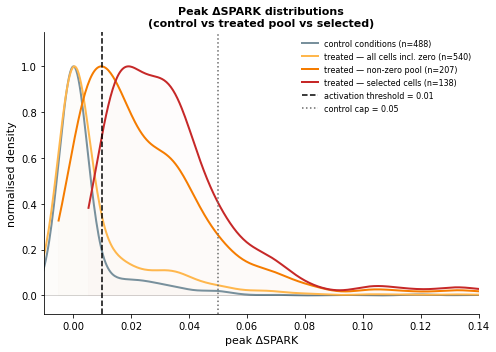

In [305]:
# ── prepare data ──────────────────────────────────────────────────────────────
ctrl_pd      = df_stats[df_stats['criteria'] == 1]['peak_delta'].values

treated_all       = df_stats[(df_stats['criteria'] == 2) & (~df_stats['all_zero'])]
treated_pd        = treated_all['peak_delta'].values
treated_pd        = treated_pd[treated_pd > 0]

# NEW: all treated including zero cells (no all_zero or >0 filter)
treated_with_zero = df_stats[df_stats['criteria'] == 2]['peak_delta'].values

treated_sel       = df_selected[df_selected['criteria'] == 2]
treated_sel_pd    = treated_sel['peak_delta'].values
treated_sel_pd    = treated_sel_pd[treated_sel_pd > 0]

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

COLORS = {
    'control':       '#78909C',   # blue-grey  — baseline / null
    'treated_zero':  '#FFB74D',   # amber      — treated full (diluted by zeros)
    'treated_nozero':'#F57C00',   # dark orange — treated non-zero (enriched)
    'selected':      '#C62828',   # deep red   — final selected (highest signal)
}

plot_kde(ax, ctrl_pd,          COLORS['control'], f'control conditions (n={len(ctrl_pd)})')
plot_kde(ax, treated_with_zero,COLORS['treated_zero'], f'treated — all cells incl. zero (n={len(treated_with_zero)})')
plot_kde(ax, treated_pd,       COLORS['treated_nozero'], f'treated — non-zero pool (n={len(treated_pd)})')
plot_kde(ax, treated_sel_pd,   COLORS['selected'], f'treated — selected cells (n={len(treated_sel_pd)})')

ax.axvline(0.01, color='black',   lw=1.5, ls='--', label='activation threshold = 0.01')
ax.axvline(0.05, color='dimgray', lw=1.5, ls=':',  label='control cap = 0.05')

ax.axhline(0, color='black', lw=0.5, alpha=0.3)
ax.set_xlim(-0.01, 0.14)
ax.set_ylim(-0.08, 1.15)
ax.set_xlabel('peak \u0394SPARK', fontsize=11)
ax.set_ylabel('normalised density', fontsize=11)
ax.set_title('Peak \u0394SPARK distributions\n(control vs treated pool vs selected)',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
curves = [
    ('Control conditions',            ctrl_pd),
    ('Treated all incl. zero',        treated_with_zero),
    ('Treated pool (non-zero)',        treated_pd),
    ('Treated selected',              treated_sel_pd),
]
out_pdf = os.path.join(SAVE_DIR, 'spark_threshold_distributions_combined_all.pdf')
fig.savefig(out_pdf, bbox_inches='tight')
print(f'Saved -> {out_pdf}')

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_threshold_distributions_combined.png
Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_threshold_distributions_combined.pdf


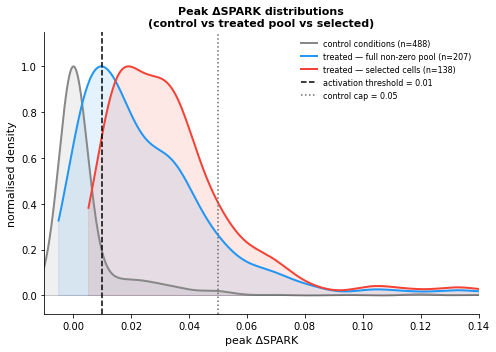


Curve                               n      mean    median       p25       p75       p90       p95       max
---------------------------------------------------------------------------------------------------------
Control conditions                488   0.00596   0.00000   0.00000   0.00000   0.02124   0.03430   0.17742
Treated pool (non-zero)           207   0.02674   0.01818   0.00839   0.03564   0.05307   0.07243   0.18946
Treated selected                  138   0.03633   0.03073   0.01690   0.04148   0.06586   0.08647   0.18946

Enrichment (treated pool → selected):
  median shift : +0.01255
  mean shift   : +0.00959
  % treated pool above activation threshold (0.01) : 71.0%
  % treated selected above activation threshold    : 100.0%


In [280]:
# ── panel 4 only: all conditions combined — control vs treated pool vs selected
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


# ── prepare data ──────────────────────────────────────────────────────────────
ctrl_pd     = df_stats[df_stats['criteria'] == 1]['peak_delta'].values

treated_all  = df_stats[(df_stats['criteria'] == 2) & (~df_stats['all_zero'])]
treated_pd   = treated_all['peak_delta'].values
treated_pd   = treated_pd[treated_pd > 0]

treated_sel  = df_selected[df_selected['criteria'] == 2]
treated_sel_pd = treated_sel['peak_delta'].values
treated_sel_pd = treated_sel_pd[treated_sel_pd > 0]

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

plot_kde(ax, ctrl_pd,       '#888888', f'control conditions (n={len(ctrl_pd)})')
plot_kde(ax, treated_pd,    '#2196F3', f'treated — full non-zero pool (n={len(treated_pd)})')
plot_kde(ax, treated_sel_pd,'#F44336', f'treated — selected cells (n={len(treated_sel_pd)})')

ax.axvline(0.01, color='black',   lw=1.5, ls='--', label='activation threshold = 0.01')
ax.axvline(0.05, color='dimgray', lw=1.5, ls=':',  label='control cap = 0.05')

ax.axhline(0, color='black', lw=0.5, alpha=0.3)
ax.set_xlim(-0.01, 0.14)
ax.set_ylim(-0.08, 1.15)
ax.set_xlabel('peak \u0394SPARK', fontsize=11)
ax.set_ylabel('normalised density', fontsize=11)
ax.set_title('Peak \u0394SPARK distributions\n(control vs treated pool vs selected)',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()

out_png = os.path.join(SAVE_DIR, 'spark_threshold_distributions_combined.png')
fig.savefig(out_png, dpi=200, bbox_inches='tight')
print(f'Saved -> {out_png}')

out_pdf = os.path.join(SAVE_DIR, 'spark_threshold_distributions_combined.pdf')
fig.savefig(out_pdf, bbox_inches='tight')
print(f'Saved -> {out_pdf}')

plt.show()

# ── statistics for each curve ─────────────────────────────────────────────────
curves = [
    ('Control conditions',         ctrl_pd),
    ('Treated pool (non-zero)',     treated_pd),
    ('Treated selected',           treated_sel_pd),
]

print(f'\n{"Curve":<30}  {"n":>5}  {"mean":>8}  {"median":>8}  '
      f'{"p25":>8}  {"p75":>8}  {"p90":>8}  {"p95":>8}  {"max":>8}')
print('-' * 105)
for name, arr in curves:
    print(f'{name:<30}  {len(arr):>5}  {arr.mean():>8.5f}  '
          f'{np.median(arr):>8.5f}  {np.percentile(arr,25):>8.5f}  '
          f'{np.percentile(arr,75):>8.5f}  {np.percentile(arr,90):>8.5f}  '
          f'{np.percentile(arr,95):>8.5f}  {arr.max():>8.5f}')

print()
print('Enrichment (treated pool \u2192 selected):')
print(f'  median shift : {np.median(treated_sel_pd) - np.median(treated_pd):+.5f}')
print(f'  mean shift   : {treated_sel_pd.mean() - treated_pd.mean():+.5f}')
print(f'  % treated pool above activation threshold (0.01) : '
      f'{(treated_pd >= 0.01).mean()*100:.1f}%')
print(f'  % treated selected above activation threshold    : '
      f'{(treated_sel_pd >= 0.01).mean()*100:.1f}%')

In [269]:
# ── statistical testing: treated vs control peak ΔSPARK ──────────────────────
import numpy as np
from scipy import stats

print('=' * 70)
print('Statistical testing: treated conditions vs control')
print('IKK-SPK-novel excluded')
print('=' * 70)

# ── 1. normality check — decide parametric vs non-parametric ─────────────────
print('\n--- Normality (Shapiro-Wilk, n capped at 5000) ---')
for name, arr in [('Control',           ctrl_pd),
                  ('Treated all',        treated_all_pd),
                  ('Treated non-zero',   treated_nz_pd),
                  ('Treated selected',   treated_sel_pd)]:
    sample = arr[np.isfinite(arr)]
    if len(sample) > 5000:
        sample = np.random.default_rng(42).choice(sample, 5000, replace=False)
    stat, p = stats.shapiro(sample)
    print(f'  {name:<25}: W={stat:.4f}  p={p:.2e}  '
          f'{"normal" if p > 0.05 else "non-normal"}')

print()
print('=> Distributions are non-normal; using Mann-Whitney U (one-sided)')
print('   H0: treated <= control   H1: treated > control')

# ── 2. Mann-Whitney U tests ───────────────────────────────────────────────────
comparisons = [
    ('Treated — all cells',     treated_all_pd),
    ('Treated — non-zero pool', treated_nz_pd),
    ('Treated — selected',      treated_sel_pd),
]

print(f'\n{"Comparison":<30}  {"U stat":>10}  {"p-value":>12}  '
      f'{"sig":>5}  {"effect r":>9}  {"ctrl med":>9}  {"trt med":>9}')
print('-' * 95)

for name, trt_arr in comparisons:
    trt  = trt_arr[np.isfinite(trt_arr)]
    ctrl = ctrl_pd[np.isfinite(ctrl_pd)]

    U, p = stats.mannwhitneyu(trt, ctrl, alternative='greater')

    # rank-biserial correlation as effect size: r = 1 - 2U/(n1*n2)
    r = 1 - (2 * U) / (len(trt) * len(ctrl))

    if p < 0.001:   sig = '***'
    elif p < 0.01:  sig = '**'
    elif p < 0.05:  sig = '*'
    else:           sig = 'ns'

    print(f'  {name:<28}  {U:>10.0f}  {p:>12.3e}  '
          f'{sig:>5}  {r:>9.4f}  {np.median(ctrl):>9.5f}  {np.median(trt):>9.5f}')

# ── 3. Kruskal-Wallis across all four groups ──────────────────────────────────
print()
print('--- Kruskal-Wallis: overall group difference ---')
H, p_kw = stats.kruskal(
    ctrl_pd[np.isfinite(ctrl_pd)],
    treated_all_pd[np.isfinite(treated_all_pd)],
    treated_nz_pd[np.isfinite(treated_nz_pd)],
    treated_sel_pd[np.isfinite(treated_sel_pd)],
)
print(f'  H={H:.4f}  p={p_kw:.2e}  '
      f'{"significant" if p_kw < 0.05 else "not significant"}')

# ── 4. post-hoc pairwise Mann-Whitney with Bonferroni correction ──────────────
print()
print('--- Pairwise Mann-Whitney U (two-sided) with Bonferroni correction ---')
groups = [
    ('Control',           ctrl_pd[np.isfinite(ctrl_pd)]),
    ('Treated all',       treated_all_pd[np.isfinite(treated_all_pd)]),
    ('Treated non-zero',  treated_nz_pd[np.isfinite(treated_nz_pd)]),
    ('Treated selected',  treated_sel_pd[np.isfinite(treated_sel_pd)]),
]
n_comparisons = len(groups) * (len(groups) - 1) // 2

print(f'  n comparisons (Bonferroni k={n_comparisons})')
print(f'  {"Group A":<25}  {"Group B":<25}  {"p raw":>10}  '
      f'{"p adj":>10}  {"sig":>5}')
print('  ' + '-' * 85)

for i in range(len(groups)):
    for j in range(i + 1, len(groups)):
        name_a, arr_a = groups[i]
        name_b, arr_b = groups[j]
        _, p_raw = stats.mannwhitneyu(arr_a, arr_b, alternative='two-sided')
        p_adj    = min(p_raw * n_comparisons, 1.0)   # Bonferroni
        if p_adj < 0.001:   sig = '***'
        elif p_adj < 0.01:  sig = '**'
        elif p_adj < 0.05:  sig = '*'
        else:               sig = 'ns'
        print(f'  {name_a:<25}  {name_b:<25}  {p_raw:>10.3e}  '
              f'{p_adj:>10.3e}  {sig:>5}')

# ── 5. summary ────────────────────────────────────────────────────────────────
print()
print('--- Summary ---')
print(f'  Control median peak \u0394SPARK          : {np.median(ctrl_pd):.5f}')
print(f'  Treated all cells median            : {np.median(treated_all_pd):.5f}')
print(f'  Treated non-zero pool median        : {np.median(treated_nz_pd):.5f}')
print(f'  Treated selected median             : {np.median(treated_sel_pd):.5f}')
print(f'  Fold median (selected / control)    : '
      f'{np.median(treated_sel_pd) / np.median(ctrl_pd[ctrl_pd > 0]):.2f}x'
      f'  (non-zero control baseline used)')

Statistical testing: treated conditions vs control
IKK-SPK-novel excluded

--- Normality (Shapiro-Wilk, n capped at 5000) ---
  Control                  : W=0.3751  p=2.93e-36  non-normal
  Treated all              : W=0.5922  p=5.35e-30  non-normal
  Treated non-zero         : W=0.7672  p=2.64e-14  non-normal
  Treated selected         : W=0.7400  p=9.83e-13  non-normal

=> Distributions are non-normal; using Mann-Whitney U (one-sided)
   H0: treated <= control   H1: treated > control

Comparison                          U stat       p-value    sig   effect r   ctrl med    trt med
-----------------------------------------------------------------------------------------------
  Treated — all cells               106118     1.708e-07    ***    -0.1626    0.00000    0.00000
  Treated — non-zero pool            61200     4.239e-63    ***    -0.8100    0.00000    0.02252
  Treated — selected                 45642     2.088e-59    ***    -0.8606    0.00000    0.03182

--- Kruskal-Wallis: ove

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_statistical_testing.png
Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_statistical_testing.pdf


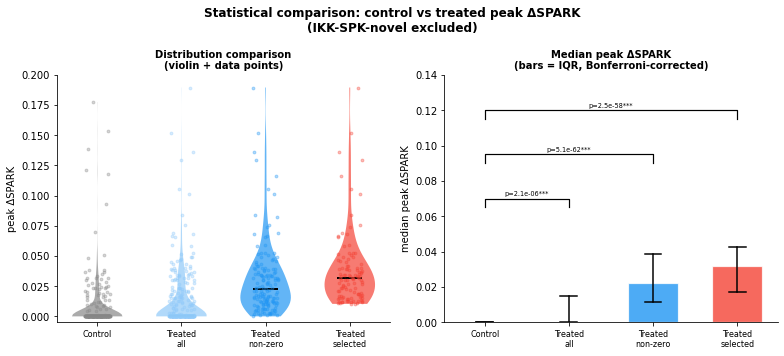

In [279]:
# ── visualise statistical testing results — panels 1 and 2 only ──────────────
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

COLORS = {
    'Control':           '#888888',
    'Treated all':       '#90CAF9',
    'Treated non-zero':  '#2196F3',
    'Treated selected':  '#F44336',
}

groups_data = [
    ('Control',          ctrl_pd[ctrl_pd >= 0]),
    ('Treated all',      treated_all_pd[treated_all_pd >= 0]),
    ('Treated non-zero', treated_nz_pd[treated_nz_pd >= 0]),
    ('Treated selected', treated_sel_pd[treated_sel_pd >= 0]),
]
group_names  = [g[0] for g in groups_data]
group_arrays = [g[1] for g in groups_data]
group_colors = [COLORS[n] for n in group_names]

# ── panel 1: violin + jittered points ────────────────────────────────────────
ax = axes[0]
parts = ax.violinplot(group_arrays, positions=range(len(group_arrays)),
                      showmedians=True, showextrema=False, widths=0.6)
for pc, color in zip(parts['bodies'], group_colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

rng = np.random.default_rng(42)
for i, (arr, color) in enumerate(zip(group_arrays, group_colors)):
    sample = arr if len(arr) <= 300 else rng.choice(arr, 300, replace=False)
    jitter = rng.uniform(-0.15, 0.15, size=len(sample))
    ax.scatter(i + jitter, sample, color=color, s=8, alpha=0.35, zorder=3)

ax.set_xticks(range(len(group_names)))
ax.set_xticklabels(['Control', 'Treated\nall', 'Treated\nnon-zero', 'Treated\nselected'],
                   fontsize=8)
ax.set_ylabel('peak \u0394SPARK', fontsize=10)
ax.set_title('Distribution comparison\n(violin + data points)', fontsize=10, fontweight='bold')
ax.set_ylim(-0.005, 0.20)
ax.spines[['top', 'right']].set_visible(False)

# ── panel 2: median bar chart with significance brackets ─────────────────────
ax = axes[1]
medians = [np.median(arr) for arr in group_arrays]
ax.bar(range(len(group_names)), medians, color=group_colors,
       alpha=0.8, width=0.6, edgecolor='white', linewidth=1.2)

q25 = [np.percentile(arr, 25) for arr in group_arrays]
q75 = [np.percentile(arr, 75) for arr in group_arrays]
for i, (med, lo, hi) in enumerate(zip(medians, q25, q75)):
    ax.plot([i, i], [lo, hi], color='black', lw=1.5, zorder=5)
    ax.plot([i - 0.1, i + 0.1], [lo, lo], color='black', lw=1.5, zorder=5)
    ax.plot([i - 0.1, i + 0.1], [hi, hi], color='black', lw=1.5, zorder=5)

sig_results = [
    (0, 1, 'p=2.1e-06***',  0.065),
    (0, 2, 'p=5.1e-62***',  0.090),
    (0, 3, 'p=2.5e-58***',  0.115),
]
for x1, x2, label, y in sig_results:
    ax.plot([x1, x1, x2, x2], [y, y + 0.005, y + 0.005, y],
            color='black', lw=1.2)
    ax.text((x1 + x2) / 2, y + 0.006, label,
            ha='center', va='bottom', fontsize=6.5)

ax.set_xticks(range(len(group_names)))
ax.set_xticklabels(['Control', 'Treated\nall', 'Treated\nnon-zero', 'Treated\nselected'],
                   fontsize=8)
ax.set_ylabel('median peak \u0394SPARK', fontsize=10)
ax.set_title('Median peak \u0394SPARK\n(bars = IQR, Bonferroni-corrected)', fontsize=10,
             fontweight='bold')
ax.set_ylim(0, 0.14)
ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Statistical comparison: control vs treated peak \u0394SPARK\n'
             '(IKK-SPK-novel excluded)',
             fontsize=12, fontweight='bold')
fig.tight_layout()

out_png = os.path.join(SAVE_DIR, 'spark_statistical_testing.png')
out_pdf = os.path.join(SAVE_DIR, 'spark_statistical_testing.pdf')
fig.savefig(out_png, dpi=200, bbox_inches='tight')
fig.savefig(out_pdf,           bbox_inches='tight')
print(f'Saved -> {out_png}')
print(f'Saved -> {out_pdf}')
plt.show()

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_ctrl_vs_treated_all.png
Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_ctrl_vs_treated_all.pdf


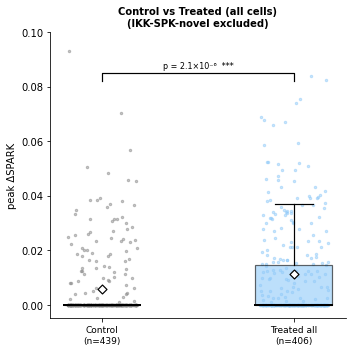

In [278]:
fig, ax = plt.subplots(figsize=(5, 5))

sub_groups = [
    ('Control',     ctrl_pd[ctrl_pd >= 0]),
    ('Treated all', treated_all_pd[treated_all_pd >= 0]),
]
sub_colors = [COLORS['Control'], COLORS['Treated all']]

rng = np.random.default_rng(42)

for i, (name, arr, color) in enumerate(zip(
        [g[0] for g in sub_groups],
        [g[1] for g in sub_groups],
        sub_colors)):

    # jittered strip
    sample = arr if len(arr) <= 400 else rng.choice(arr, 400, replace=False)
    jitter = rng.uniform(-0.18, 0.18, size=len(sample))
    ax.scatter(i + jitter, sample, color=color, s=6, alpha=0.50, zorder=2)

    # box: Q25–Q75
    q25, q50, q75 = np.percentile(arr, [25, 50, 75])
    iqr = q75 - q25
    whisker_lo = max(arr.min(), q25 - 1.5 * iqr)
    whisker_hi = min(arr.max(), q75 + 1.5 * iqr)

    # box rectangle
    box = plt.Rectangle((i - 0.2, q25), 0.4, q75 - q25,
                         facecolor=color, alpha=0.6,
                         edgecolor='black', linewidth=1.2, zorder=3)
    ax.add_patch(box)

    # median line
    ax.plot([i - 0.2, i + 0.2], [q50, q50],
            color='black', lw=2.0, zorder=4)

    # whiskers
    ax.plot([i, i], [whisker_lo, q25], color='black', lw=1.2, zorder=3)
    ax.plot([i, i], [q75, whisker_hi], color='black', lw=1.2, zorder=3)
    ax.plot([i - 0.1, i + 0.1], [whisker_lo, whisker_lo],
            color='black', lw=1.2, zorder=3)
    ax.plot([i - 0.1, i + 0.1], [whisker_hi, whisker_hi],
            color='black', lw=1.2, zorder=3)

    # mean diamond
    ax.scatter(i, arr.mean(), marker='D', color='white',
               edgecolor='black', s=40, zorder=5, linewidth=1.2)

# significance bracket
y_bracket = 0.082
ax.plot([0, 0, 1, 1],
        [y_bracket, y_bracket + 0.003, y_bracket + 0.003, y_bracket],
        color='black', lw=1.2)
ax.text(0.5, y_bracket + 0.004, 'p = 2.1×10⁻⁶  ***',
        ha='center', va='bottom', fontsize=8)

ax.set_xticks([0, 1])
ax.set_xticklabels(
    [f'Control\n(n={len(sub_groups[0][1])})',
     f'Treated all\n(n={len(sub_groups[1][1])})'],
    fontsize=9)
ax.set_ylabel('peak \u0394SPARK', fontsize=10)
ax.set_ylim(-0.005, 0.10)
ax.set_title('Control vs Treated (all cells)\n(IKK-SPK-novel excluded)',
             fontsize=10, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()

out_png = os.path.join(SAVE_DIR, 'spark_ctrl_vs_treated_all.png')
fig.savefig(out_png, dpi=200, bbox_inches='tight')
print(f'Saved -> {out_png}')

out_pdf = os.path.join(SAVE_DIR, 'spark_ctrl_vs_treated_all.pdf')
fig.savefig(out_pdf, bbox_inches='tight')
print(f'Saved -> {out_pdf}')

plt.show()

In [277]:
SAVE_DIR

'${SPARK_ACQUISITION_ROOT}/spark_examples/figures'

In [213]:
ACTIVATION_THRESH  = 0.01   # was 0.02 — recovers cells with modest response
N_CELLS            = 30     # was 20 — stops truncating TBK-SPK-novel/diABZI

In [214]:
# ── per-cell summary for selection ───────────────────────────────────────────
# Changes vs previous version:
#   - basal  (criteria=1): take ALL cells below BASAL_PEAK_CAP (no N_CELLS cap)
#   - activated (criteria=2): ACTIVATION_THRESH lowered to 0.01, cap at N_CELLS

f0_vals = (df_all[df_all['frame'] == 0]
           .groupby(['run_key','cell_id'])['spark_signal']
           .first().rename('f0_abs').reset_index())
high_baseline = f0_vals[(f0_vals['f0_abs'] > BASELINE_SPARK_THRESH) &
                         (f0_vals['f0_abs'] > 0)]
exclude_idx   = set(zip(high_baseline['run_key'], high_baseline['cell_id']))
print(f'Cells dropped (pre-activated baseline > {BASELINE_SPARK_THRESH}): '
      f'{len(high_baseline)}')

cell_stats = []
for (rk, cid), grp in df_all.groupby(['run_key','cell_id']):
    if (rk, cid) in exclude_idx:
        continue
    grp      = grp.sort_values('frame')
    trace    = grp['spark_smoothed'].values
    reporter = grp['reporter'].iloc[0]
    cond     = grp['condition'].iloc[0]
    key      = (reporter, cond)
    if key not in SELECTION_CRITERIA:
        continue
    steps      = np.abs(np.diff(trace))
    smoothness = 1.0 / (steps.mean() + 1e-9)
    peak_delta = trace.max()
    late_mean  = trace[len(trace) // 3:].mean()
    cell_stats.append({
        'run_key':    rk,
        'cell_id':    cid,
        'reporter':   reporter,
        'condition':  cond,
        'criteria':   SELECTION_CRITERIA[key],
        'smoothness': float(smoothness),
        'peak_delta': float(peak_delta),
        'late_mean':  float(late_mean),
        'all_zero':   bool((grp['spark_signal'] == 0).all()),
    })

df_stats = pd.DataFrame(cell_stats)

ACTIVATION_THRESH = 0.01   # lowered from 0.02

selected = []
for (reporter, cond, criteria), grp in df_stats.groupby(
        ['reporter','condition','criteria']):

    if criteria == 1:
        # basal: take ALL cells below the peak cap — no N_CELLS truncation
        pool = grp[grp['peak_delta'] <= BASAL_PEAK_CAP]
        if len(pool) == 0:
            print(f'  [basal] {reporter:20s} / {cond:15s} -> '
                  f'NO cells below cap {BASAL_PEAK_CAP} — skipping')
            continue
        pool   = pool.copy()
        pool['sort_zero'] = pool['all_zero'].map({True: 0, False: 1})
        ranked = pool.sort_values(['sort_zero','peak_delta','smoothness'],
                                   ascending=[True, True, False])
        chosen = ranked          # ← ALL passing cells, no head(N_CELLS)

    else:
        # activated: exclude all-zero cells, rank by response
        pool = grp[~grp['all_zero']]
        if len(pool) == 0:
            print(f'  [activated] {reporter:20s} / {cond:15s} -> '
                  f'NO non-zero cells — skipping')
            continue
        above  = pool[pool['peak_delta'] >= ACTIVATION_THRESH]
        pool   = above if len(above) >= 3 else pool
        ranked = pool.sort_values(['late_mean','smoothness'],
                                   ascending=[False, False])
        chosen = ranked.head(N_CELLS)

    crit_label = 'basal' if criteria == 1 else 'activated'
    selected.append(chosen)
    n_zero = chosen['all_zero'].sum()
    print(f'  [{crit_label}] {reporter:20s} / {cond:15s} '
          f'-> {len(chosen)} cells '
          f'(zero-signal: {n_zero})  '
          f'peak [{chosen["peak_delta"].min():.4f}–'
          f'{chosen["peak_delta"].max():.4f}]')

df_selected = pd.concat(selected, ignore_index=True)
print(f'\nTotal selected: {len(df_selected)} cells across '
      f'{df_selected[["reporter","condition"]].drop_duplicates().shape[0]} '
      f'conditions')

for rk, cid, label in [('0731p2-62', 2, 'activated TBK-SPK-1/diABZI'),
                         ('240731p2-50', 1, 'zero-signal TBK-SPK-1/blank')]:
    inc = df_selected[(df_selected['run_key']==rk) &
                       (df_selected['cell_id']==cid)]
    print(f'  {rk} cell {cid} ({label}): '
          f'{"INCLUDED" if len(inc)>0 else "NOT included"}')

Cells dropped (pre-activated baseline > 0.2): 4
  [basal] IKK-SPK-1            / BMS-345541      -> 14 cells (zero-signal: 11)  peak [0.0000–0.0308]
  [basal] IKK-SPK-1            / GSK8612         -> 28 cells (zero-signal: 14)  peak [0.0000–0.0384]
  [activated] IKK-SPK-1            / TNFa            -> 11 cells (zero-signal: 0)  peak [0.0125–0.0658]
  [basal] IKK-SPK-1            / blank           -> 46 cells (zero-signal: 26)  peak [-0.0188–0.0332]
  [activated] IKK-SPK-1            / diABZI          -> 6 cells (zero-signal: 0)  peak [0.0119–0.0740]
  [activated] IKK-SPK-1            / polyIC          -> 24 cells (zero-signal: 0)  peak [0.0103–0.0678]
  [basal] IKK-SPK-1-TA         / TNFa            -> 19 cells (zero-signal: 8)  peak [0.0000–0.0300]
  [basal] IKK-SPK-1-TA         / blank           -> 5 cells (zero-signal: 4)  peak [0.0000–0.0000]
  [basal] IKK-SPK-1-TA         / diABZI          -> 29 cells (zero-signal: 22)  peak [0.0000–0.0457]
  [basal] IKK-SPK-novel        / BMS-

In [215]:
# ── cell counts before and after selection, per (reporter, condition) ─────────

# BEFORE: df_stats (all cells that passed all filters and have a SELECTION_CRITERIA key)
print("BEFORE SELECTION (df_stats):")
print(f"{'reporter':<22} {'condition':<16} {'criteria':<10} {'n_cells':>8} {'n_nonzero':>10} {'peak_range'}")
print("-" * 90)

before = (df_stats.groupby(['reporter','condition','criteria'])
          .apply(lambda g: pd.Series({
              'n_cells':   len(g),
              'n_nonzero': (~g['all_zero']).sum(),
              'peak_min':  g['peak_delta'].min(),
              'peak_max':  g['peak_delta'].max(),
          }))
          .reset_index()
          .sort_values(['reporter','condition']))

for _, r in before.iterrows():
    crit = 'basal' if r['criteria']==1 else 'activated'
    print(f"  {r['reporter']:<20} {r['condition']:<16} {crit:<10} "
          f"{int(r['n_cells']):>8} {int(r['n_nonzero']):>10}   "
          f"[{r['peak_min']:.4f}–{r['peak_max']:.4f}]")

# AFTER: df_selected
print(f"\nAFTER SELECTION (df_selected, top {N_CELLS}):")
print(f"{'reporter':<22} {'condition':<16} {'criteria':<10} {'n_selected':>10} {'n_nonzero':>10} {'peak_range'}")
print("-" * 90)

after = (df_selected.groupby(['reporter','condition','criteria'])
         .apply(lambda g: pd.Series({
             'n_selected': len(g),
             'n_nonzero':  (~g['all_zero']).sum(),
             'peak_min':   g['peak_delta'].min(),
             'peak_max':   g['peak_delta'].max(),
         }))
         .reset_index()
         .sort_values(['reporter','condition']))

for _, r in after.iterrows():
    crit = 'basal' if r['criteria']==1 else 'activated'
    print(f"  {r['reporter']:<20} {r['condition']:<16} {crit:<10} "
          f"{int(r['n_selected']):>10} {int(r['n_nonzero']):>10}   "
          f"[{r['peak_min']:.4f}–{r['peak_max']:.4f}]")

# DELTA: show how many were dropped by selection cap
print(f"\nDROPPED BY SELECTION (before − after):")
print(f"{'reporter':<22} {'condition':<16} {'before':>8} {'after':>7} {'dropped':>8}")
print("-" * 70)
merged = before.merge(after[['reporter','condition','n_selected']],
                      on=['reporter','condition'], how='left')
merged['n_selected'] = merged['n_selected'].fillna(0).astype(int)
merged['dropped']    = merged['n_cells'].astype(int) - merged['n_selected']
for _, r in merged.sort_values('dropped', ascending=False).iterrows():
    if r['dropped'] != 0:
        print(f"  {r['reporter']:<20} {r['condition']:<16} "
              f"{int(r['n_cells']):>8} {int(r['n_selected']):>7} {int(r['dropped']):>8}")

BEFORE SELECTION (df_stats):
reporter               condition        criteria    n_cells  n_nonzero peak_range
------------------------------------------------------------------------------------------
  IKK-SPK-1            BMS-345541       basal            15          4   [0.0000–0.0508]
  IKK-SPK-1            GSK8612          basal            31         17   [0.0000–0.1774]
  IKK-SPK-1            TNFa             activated        42         15   [0.0000–0.0658]
  IKK-SPK-1            blank            basal            47         21   [-0.0188–0.0567]
  IKK-SPK-1            diABZI           activated        21         12   [0.0000–0.0740]
  IKK-SPK-1            polyIC           activated        82         42   [-0.0381–0.0678]
  IKK-SPK-1-TA         TNFa             basal            19         11   [0.0000–0.0300]
  IKK-SPK-1-TA         blank            basal             5          1   [0.0000–0.0000]
  IKK-SPK-1-TA         diABZI           basal            31          9   [0.0000–0.0

In [216]:
# ── diagnose exact reason for dropping per (reporter, condition) ──────────────

print(f"{'reporter':<22} {'condition':<16} {'crit':<5} "
      f"{'total':>6} {'nonzero':>8} {'above_thresh':>13} {'selected':>9}  reason")
print("-" * 100)

for (reporter, cond, criteria), grp in df_stats.groupby(
        ['reporter','condition','criteria']):

    n_total   = len(grp)
    n_nonzero = (~grp['all_zero']).sum()
    sel       = df_selected[(df_selected['reporter']==reporter) &
                             (df_selected['condition']==cond)]
    n_sel     = len(sel)
    dropped   = n_total - n_sel
    if dropped == 0:
        continue

    crit_label = 'basal' if criteria == 1 else 'activ'

    if criteria == 1:
        n_below_cap = (grp['peak_delta'] <= BASAL_PEAK_CAP).sum()
        reason = (f"cap={BASAL_PEAK_CAP}: {n_below_cap} below → top{N_CELLS}"
                  if n_below_cap > N_CELLS
                  else f"cap={BASAL_PEAK_CAP}: only {n_below_cap} below cap")
        print(f"  {reporter:<20} {cond:<16} {crit_label:<5} "
              f"{n_total:>6} {n_nonzero:>8} {'—':>13} {n_sel:>9}  {reason}")
    else:
        pool    = grp[~grp['all_zero']]
        n_pool  = len(pool)
        above   = pool[pool['peak_delta'] >= ACTIVATION_THRESH]
        n_above = len(above)
        if n_pool == 0:
            reason = "ALL ZERO — no non-zero cells"
        elif n_above >= 3:
            reason = (f"above thresh({ACTIVATION_THRESH}): {n_above}/{n_pool} → top{N_CELLS}"
                      if n_above > N_CELLS
                      else f"above thresh({ACTIVATION_THRESH}): only {n_above} → all taken")
        else:
            reason = (f"above thresh({ACTIVATION_THRESH}): {n_above}<3 → fallback pool "
                      f"{n_pool} → top{N_CELLS}")
        print(f"  {reporter:<20} {cond:<16} {crit_label:<5} "
              f"{n_total:>6} {n_nonzero:>8} {n_above:>13} {n_sel:>9}  {reason}")

reporter               condition        crit   total  nonzero  above_thresh  selected  reason
----------------------------------------------------------------------------------------------------
  IKK-SPK-1            BMS-345541       basal     15        4             —        14  cap=0.05: only 14 below cap
  IKK-SPK-1            GSK8612          basal     31       17             —        28  cap=0.05: only 28 below cap
  IKK-SPK-1            TNFa             activ     42       15            11        11  above thresh(0.01): only 11 → all taken
  IKK-SPK-1            blank            basal     47       21             —        46  cap=0.05: 46 below → top30
  IKK-SPK-1            diABZI           activ     21       12             6         6  above thresh(0.01): only 6 → all taken
  IKK-SPK-1            polyIC           activ     82       42            24        24  above thresh(0.01): only 24 → all taken
  IKK-SPK-1-TA         diABZI           basal     31        9             —      

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_TBK1_overlay.pdf


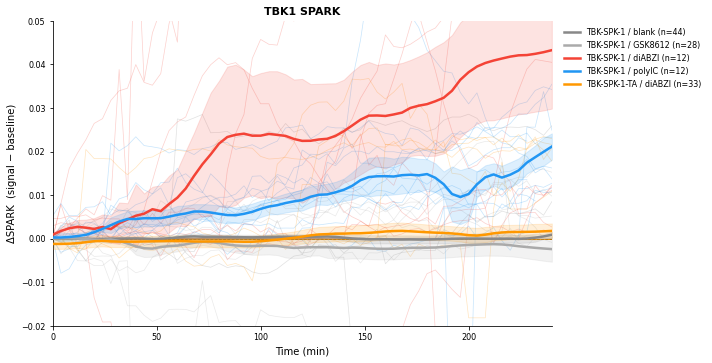

In [292]:
# ── multi-condition overlay: selected conditions on one axes ──────────────────
OVERLAY_CONDITIONS = [
    ('TBK-SPK-1',    'blank'),
    ('TBK-SPK-1',    'GSK8612'),
    ('TBK-SPK-1',    'diABZI'),
    ('TBK-SPK-1',    'polyIC'),
    ('TBK-SPK-1-TA', 'diABZI'),
]

# distinct colours per (reporter, condition) pair
OVERLAY_COLORS = {
    ('TBK-SPK-1',    'blank'):   '#888888',
    ('TBK-SPK-1',    'GSK8612'): '#aaaaaa',
    ('TBK-SPK-1',    'diABZI'):  '#F44336',
    ('TBK-SPK-1',    'polyIC'):  '#2196F3',
    ('TBK-SPK-1-TA', 'diABZI'):  '#FF9800',
}


# ── resample helper ───────────────────────────────────────────────────────────
COMMON_TIME = np.linspace(0, 240, 61)   # 4-min reference grid

def resample_trace(cell_time, cell_vals, target_time=COMMON_TIME):
    out = np.full(len(target_time), np.nan)
    t_min, t_max = cell_time.min(), cell_time.max()
    mask = (target_time >= t_min) & (target_time <= t_max)
    if mask.sum() >= 2:
        out[mask] = np.interp(target_time[mask], cell_time, cell_vals)
    return out

fig, ax = plt.subplots(figsize=(10, 5))

for rep, cond in OVERLAY_CONDITIONS:
    color    = OVERLAY_COLORS[(rep, cond)]
    sel_cond = df_selected[(df_selected['reporter'] == rep) &
                            (df_selected['condition'] == cond)]
    if len(sel_cond) == 0:
        print(f'No selected cells for {rep} / {cond}')
        continue

    trace_mat = []
    for _, row in sel_cond.iterrows():
        grp = (df_all[(df_all['run_key'] == row['run_key']) &
                      (df_all['cell_id'] == row['cell_id'])]
               .sort_values('time_min'))
        tr = resample_trace(grp['time_min'].values,
                            grp['spark_smoothed'].values)
        trace_mat.append(tr)
        ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)

    if trace_mat:
        mat      = np.array(trace_mat)
        n_obs    = np.sum(~np.isnan(mat), axis=0).clip(1)
        coverage = n_obs / mat.shape[0]
        mean_t   = np.nanmean(mat, axis=0)
        sem      = np.nanstd(mat, axis=0) / np.sqrt(n_obs)

        good   = coverage >= 0.5
        mean_m = np.where(good, mean_t, np.nan)
        sem_m  = np.where(good, sem,    np.nan)

        fitted = np.full_like(mean_m, np.nan)
        valid  = ~np.isnan(mean_m)
        if valid.sum() > SAVGOL_WINDOW:
            fitted[valid] = savgol_filter(mean_m[valid], SAVGOL_WINDOW, SAVGOL_POLY)
        else:
            fitted = mean_m

        label = f'{rep} / {cond} (n={mat.shape[0]})'
        ax.plot(COMMON_TIME, fitted, color=color, lw=2.5, zorder=5, label=label)
        ax.fill_between(COMMON_TIME, fitted - sem_m, fitted + sem_m,
                        color=color, alpha=0.15, zorder=4)
        ax.plot(COMMON_TIME[~good], fitted[~good],
                color=color, lw=1.5, ls=':', zorder=4, alpha=0.5)

ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.35)
ax.set_xlabel('Time (min)', fontsize=10)
ax.set_ylabel('ΔSPARK  (signal − baseline)', fontsize=10)
ax.spines[['top','right']].set_visible(False)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(labelsize=8)

ax.set_xlim(0, 240)
ax.set_ylim(-0.020, 0.05)
plt.tight_layout()
ax.set_title('TBK1 SPARK', fontsize=11, fontweight='bold')
path = os.path.join(SAVE_DIR, 'spark_TBK1_overlay.pdf')
plt.savefig(path, dpi=200, bbox_inches='tight')
print(f'Saved -> {path}')


plt.show()


Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_TBKnovel_overlay.pdf


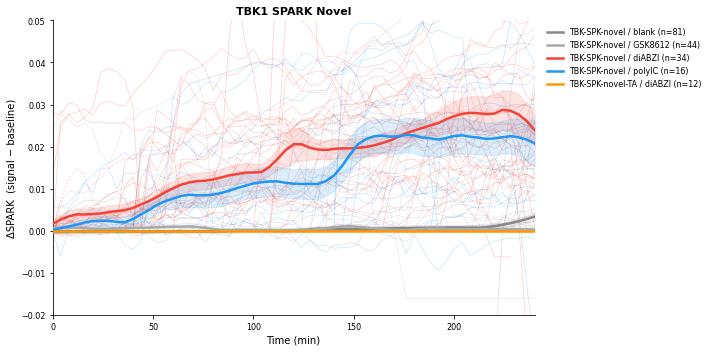

In [291]:
# ── TBK-SPK-novel overlay — diABZI augmented with manual curated traces ───────
COMMON_TIME = np.linspace(0, 240, 61)
OVERLAY_CONDITIONS = [
    ('TBK-SPK-novel',    'blank'),
    ('TBK-SPK-novel',    'GSK8612'),
    ('TBK-SPK-novel',    'diABZI'),
    ('TBK-SPK-novel',    'polyIC'),
    ('TBK-SPK-novel-TA', 'diABZI'),
]
OVERLAY_COLORS = {
    ('TBK-SPK-novel',    'blank'):   '#888888',
    ('TBK-SPK-novel',    'GSK8612'): '#aaaaaa',
    ('TBK-SPK-novel',    'diABZI'):  '#F44336',
    ('TBK-SPK-novel',    'polyIC'):  '#2196F3',
    ('TBK-SPK-novel-TA', 'diABZI'):  '#FF9800',
}
fig, ax = plt.subplots(figsize=(10, 5))
for rep, cond in OVERLAY_CONDITIONS:
    color     = OVERLAY_COLORS[(rep, cond)]
    trace_mat = []

    # ── pipeline selected traces ──────────────────────────────────────────────
    sel_cond = df_selected[(df_selected['reporter'] == rep) &
                            (df_selected['condition'] == cond)]
    for _, row in sel_cond.iterrows():
        grp = (df_all[(df_all['run_key'] == row['run_key']) &
                      (df_all['cell_id']  == row['cell_id'])]
               .sort_values('time_min'))
        tr = resample_trace(grp['time_min'].values,
                            grp['spark_smoothed'].values)
        trace_mat.append(tr)
        ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)

    # ── APPEND manual traces for TBK-SPK-novel / diABZI ──────────────────────
    if (rep, cond) == ('TBK-SPK-novel', 'diABZI'):
        df_src   = df_manual[('TBK-SPK-novel', 'diABZI')]
        n_manual = df_src[['fov', 'cell_id']].drop_duplicates().shape[0]
        for (fov, cid), grp in df_src.groupby(['fov', 'cell_id']):
            grp = grp.sort_values('time_min')
            tr  = resample_trace(grp['time_min'].values,
                                 grp['spark_delta'].values)
            trace_mat.append(tr)
            ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25, ls='--')
        label_suffix = f'n={len(sel_cond) + n_manual}'
    else:
        label_suffix = f'n={len(sel_cond)}'

    if len(trace_mat) == 0:
        print(f'No cells for {rep} / {cond}')
        continue

    fitted, sem_m, good, n = build_trace_mat(ax, color, trace_mat)
    label = f'{rep} / {cond} ({label_suffix})'
    ax.plot(COMMON_TIME, fitted, color=color, lw=2.5, zorder=5, label=label)
    ax.fill_between(COMMON_TIME, fitted - sem_m, fitted + sem_m,
                    color=color, alpha=0.15, zorder=4)
    ax.plot(COMMON_TIME[~good], fitted[~good],
            color=color, lw=1.5, ls=':', zorder=4, alpha=0.5)

ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.35)
ax.set_xlabel('Time (min)', fontsize=10)
ax.set_ylabel('\u0394SPARK  (signal \u2212 baseline)', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(labelsize=8)
ax.set_xlim(0, 240)
ax.set_ylim(-0.020, 0.05)
ax.set_title('TBK1 SPARK Novel',
             fontsize=11, fontweight='bold')
fig.tight_layout()
path = os.path.join(SAVE_DIR, 'spark_TBKnovel_overlay.pdf')
plt.savefig(path, bbox_inches='tight')
print(f'Saved -> {path}')
plt.show()

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_IKKnovel_overlay.pdf


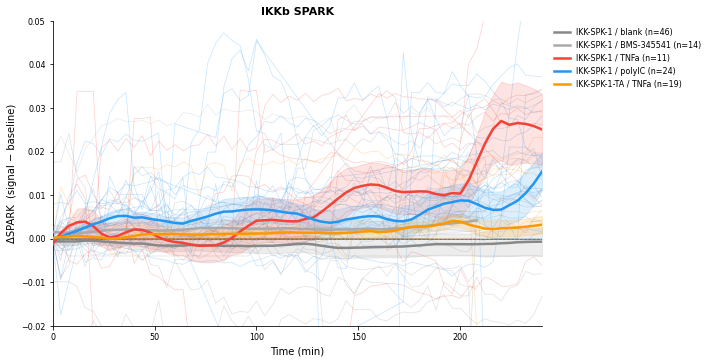

In [293]:
# ── multi-condition overlay: selected conditions on one axes ──────────────────
OVERLAY_CONDITIONS = [
    ('IKK-SPK-1', 'blank'),
    ('IKK-SPK-1', 'BMS-345541'),
    ('IKK-SPK-1', 'TNFa'),
    ('IKK-SPK-1', 'polyIC'),
    ('IKK-SPK-1-TA', 'TNFa'),
]
# distinct colours per (reporter, condition) pair
OVERLAY_COLORS = {
    ('IKK-SPK-1', 'blank'):   '#888888',
    ('IKK-SPK-1', 'BMS-345541'): '#aaaaaa',
    ('IKK-SPK-1', 'TNFa'):  '#F44336',
    ('IKK-SPK-1', 'polyIC'):  '#2196F3',
    ('IKK-SPK-1-TA', 'TNFa'):    '#FF9800',
}
# ── resample helper ───────────────────────────────────────────────────────────
COMMON_TIME = np.linspace(0, 240, 61)   # 4-min reference grid
def resample_trace(cell_time, cell_vals, target_time=COMMON_TIME):
    out = np.full(len(target_time), np.nan)
    t_min, t_max = cell_time.min(), cell_time.max()
    mask = (target_time >= t_min) & (target_time <= t_max)
    if mask.sum() >= 2:
        out[mask] = np.interp(target_time[mask], cell_time, cell_vals)
    return out
fig, ax = plt.subplots(figsize=(10, 5))
for rep, cond in OVERLAY_CONDITIONS:
    color    = OVERLAY_COLORS[(rep, cond)]
    sel_cond = df_selected[(df_selected['reporter'] == rep) &
                            (df_selected['condition'] == cond)]
    if len(sel_cond) == 0:
        print(f'No selected cells for {rep} / {cond}')
        continue
    trace_mat = []
    for _, row in sel_cond.iterrows():
        grp = (df_all[(df_all['run_key'] == row['run_key']) &
                      (df_all['cell_id'] == row['cell_id'])]
               .sort_values('time_min'))
        tr = resample_trace(grp['time_min'].values,
                            grp['spark_smoothed'].values)
        trace_mat.append(tr)
        ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)
    if trace_mat:
        mat      = np.array(trace_mat)
        n_obs    = np.sum(~np.isnan(mat), axis=0).clip(1)
        coverage = n_obs / mat.shape[0]
        mean_t   = np.nanmean(mat, axis=0)
        sem      = np.nanstd(mat, axis=0) / np.sqrt(n_obs)
        good   = coverage >= 0.5
        mean_m = np.where(good, mean_t, np.nan)
        sem_m  = np.where(good, sem,    np.nan)
        fitted = np.full_like(mean_m, np.nan)
        valid  = ~np.isnan(mean_m)
        if valid.sum() > SAVGOL_WINDOW:
            fitted[valid] = savgol_filter(mean_m[valid], SAVGOL_WINDOW, SAVGOL_POLY)
        else:
            fitted = mean_m
        label = f'{rep} / {cond} (n={mat.shape[0]})'
        ax.plot(COMMON_TIME, fitted, color=color, lw=2.5, zorder=5, label=label)
        ax.fill_between(COMMON_TIME, fitted - sem_m, fitted + sem_m,
                        color=color, alpha=0.15, zorder=4)
        ax.plot(COMMON_TIME[~good], fitted[~good],
                color=color, lw=1.5, ls=':', zorder=4, alpha=0.5)
ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.35)
ax.set_xlabel('Time (min)', fontsize=10)
ax.set_ylabel('ΔSPARK  (signal − baseline)', fontsize=10)
ax.spines[['top','right']].set_visible(False)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(labelsize=8)
ax.set_ylim(-0.02, 0.05)
ax.set_xlim(0, 240)
plt.tight_layout()
ax.set_title('IKKb SPARK', fontsize=11, fontweight='bold')
path = os.path.join(SAVE_DIR, 'spark_IKKnovel_overlay.pdf')
plt.savefig(path, dpi=200, bbox_inches='tight')
print(f'Saved -> {path}')
plt.show()

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_IKKnovel_overlay_2.pdf


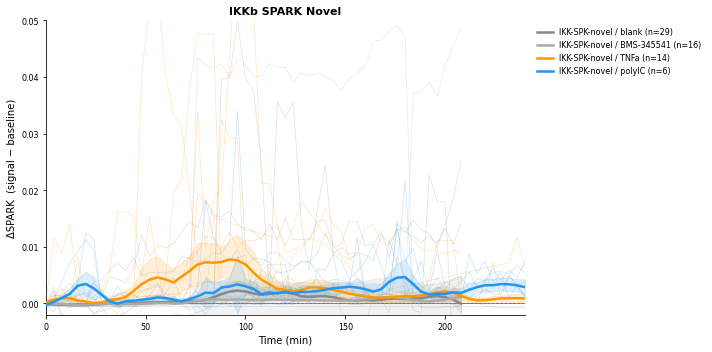

In [295]:
# ── IKK-SPK-novel overlay — polyIC replaced, TBK-SPK-novel diABZI augmented ──
COMMON_TIME = np.linspace(0, 240, 61)

OVERLAY_CONDITIONS = [
    ('IKK-SPK-novel', 'blank'),
    ('IKK-SPK-novel', 'BMS-345541'),
    ('IKK-SPK-novel', 'TNFa'),
    ('IKK-SPK-novel', 'polyIC'),   # ← fully replaced by manual
]
OVERLAY_COLORS = {
    ('IKK-SPK-novel', 'blank'):   '#888888',
    ('IKK-SPK-novel', 'BMS-345541'): '#aaaaaa',
    ('IKK-SPK-novel', 'polyIC'):  '#2196F3',
    ('IKK-SPK-novel', 'TNFa'):    '#FF9800',
}

def resample_trace(cell_time, cell_vals, target_time=COMMON_TIME):
    out = np.full(len(target_time), np.nan)
    t_min, t_max = cell_time.min(), cell_time.max()
    mask = (target_time >= t_min) & (target_time <= t_max)
    if mask.sum() >= 2:
        out[mask] = np.interp(target_time[mask], cell_time, cell_vals)
    return out

def build_trace_mat(ax, color, trace_mat_in):
    """Compute and plot mean±SEM fitted line from a list of resampled traces."""
    mat      = np.array(trace_mat_in)
    n_obs    = np.sum(~np.isnan(mat), axis=0).clip(1)
    coverage = n_obs / mat.shape[0]
    mean_t   = np.nanmean(mat, axis=0)
    sem      = np.nanstd(mat, axis=0) / np.sqrt(n_obs)
    good     = coverage >= 0.5
    mean_m   = np.where(good, mean_t, np.nan)
    sem_m    = np.where(good, sem,    np.nan)
    fitted   = np.full_like(mean_m, np.nan)
    valid    = ~np.isnan(mean_m)
    if valid.sum() > SAVGOL_WINDOW:
        fitted[valid] = savgol_filter(mean_m[valid], SAVGOL_WINDOW, SAVGOL_POLY)
    else:
        fitted = mean_m
    return fitted, sem_m, good, mat.shape[0]

fig, ax = plt.subplots(figsize=(10, 5))

for rep, cond in OVERLAY_CONDITIONS:
    color     = OVERLAY_COLORS[(rep, cond)]
    trace_mat = []

    if (rep, cond) == ('IKK-SPK-novel', 'polyIC'):
        # ── FULLY REPLACED: use manual curated traces only ────────────────────
        df_src = df_manual[('IKK-SPK-novel', 'polyIC')]
        for (fov, cid), grp in df_src.groupby(['fov', 'cell_id']):
            grp = grp.sort_values('time_min')
            tr  = resample_trace(grp['time_min'].values,
                                 grp['spark_delta'].values)
            trace_mat.append(tr)
            ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)
        source_note = 'manual'

    else:
        # ── pipeline selected traces ──────────────────────────────────────────
        sel_cond = df_selected[(df_selected['reporter'] == rep) &
                                (df_selected['condition'] == cond)]
        if len(sel_cond) == 0:
            print(f'No selected cells for {rep} / {cond}')
            continue
        for _, row in sel_cond.iterrows():
            grp = (df_all[(df_all['run_key'] == row['run_key']) &
                          (df_all['cell_id']  == row['cell_id'])]
                   .sort_values('time_min'))
            tr = resample_trace(grp['time_min'].values,
                                grp['spark_smoothed'].values)
            trace_mat.append(tr)
            ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)
        source_note = 'pipeline'

    if trace_mat:
        fitted, sem_m, good, n = build_trace_mat(ax, color, trace_mat)
        label = f'{rep} / {cond} (n={n})'
        ax.plot(COMMON_TIME, fitted, color=color, lw=2.5, zorder=5, label=label)
        ax.fill_between(COMMON_TIME, fitted - sem_m, fitted + sem_m,
                        color=color, alpha=0.15, zorder=4)
        ax.plot(COMMON_TIME[~good], fitted[~good],
                color=color, lw=1.5, ls=':', zorder=4, alpha=0.5)

ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.35)
ax.set_xlabel('Time (min)', fontsize=10)
ax.set_ylabel('ΔSPARK  (signal − baseline)', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(labelsize=8)
ax.set_ylim(-0.002, 0.05)
ax.set_xlim(0, 240)
ax.set_title('IKKb SPARK Novel', fontsize=11, fontweight='bold')
fig.tight_layout()
path = os.path.join(SAVE_DIR, 'spark_IKKnovel_overlay_2.pdf')
plt.savefig(path, dpi=200, bbox_inches='tight')
print(f'Saved -> {path}')
plt.show()

Saved -> ${SPARK_ACQUISITION_ROOT}/spark_examples/figures/spark_IKKnovel_overlay_1.pdf


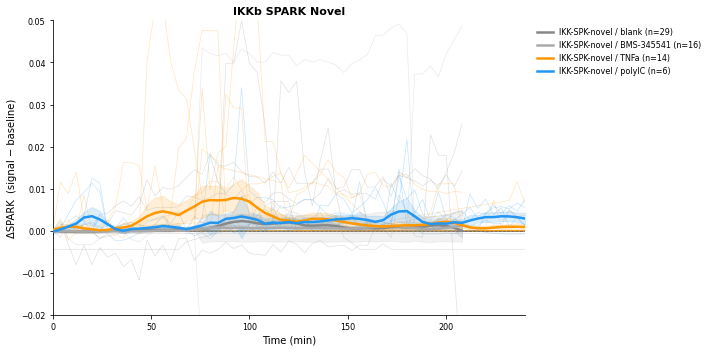

In [296]:
# ── IKK-SPK-novel overlay — polyIC replaced, TBK-SPK-novel diABZI augmented ──
COMMON_TIME = np.linspace(0, 240, 61)

OVERLAY_CONDITIONS = [
    ('IKK-SPK-novel', 'blank'),
    ('IKK-SPK-novel', 'BMS-345541'),
    ('IKK-SPK-novel', 'TNFa'),
    ('IKK-SPK-novel', 'polyIC'),   # ← fully replaced by manual
]
OVERLAY_COLORS = {
    ('IKK-SPK-novel', 'blank'):   '#888888',
    ('IKK-SPK-novel', 'BMS-345541'): '#aaaaaa',
    ('IKK-SPK-novel', 'polyIC'):  '#2196F3',
    ('IKK-SPK-novel', 'TNFa'):    '#FF9800',
}

def resample_trace(cell_time, cell_vals, target_time=COMMON_TIME):
    out = np.full(len(target_time), np.nan)
    t_min, t_max = cell_time.min(), cell_time.max()
    mask = (target_time >= t_min) & (target_time <= t_max)
    if mask.sum() >= 2:
        out[mask] = np.interp(target_time[mask], cell_time, cell_vals)
    return out

def build_trace_mat(ax, color, trace_mat_in):
    """Compute and plot mean±SEM fitted line from a list of resampled traces."""
    mat      = np.array(trace_mat_in)
    n_obs    = np.sum(~np.isnan(mat), axis=0).clip(1)
    coverage = n_obs / mat.shape[0]
    mean_t   = np.nanmean(mat, axis=0)
    sem      = np.nanstd(mat, axis=0) / np.sqrt(n_obs)
    good     = coverage >= 0.5
    mean_m   = np.where(good, mean_t, np.nan)
    sem_m    = np.where(good, sem,    np.nan)
    fitted   = np.full_like(mean_m, np.nan)
    valid    = ~np.isnan(mean_m)
    if valid.sum() > SAVGOL_WINDOW:
        fitted[valid] = savgol_filter(mean_m[valid], SAVGOL_WINDOW, SAVGOL_POLY)
    else:
        fitted = mean_m
    return fitted, sem_m, good, mat.shape[0]

fig, ax = plt.subplots(figsize=(10, 5))

for rep, cond in OVERLAY_CONDITIONS:
    color     = OVERLAY_COLORS[(rep, cond)]
    trace_mat = []

    if (rep, cond) == ('IKK-SPK-novel', 'polyIC'):
        # ── FULLY REPLACED: use manual curated traces only ────────────────────
        df_src = df_manual[('IKK-SPK-novel', 'polyIC')]
        for (fov, cid), grp in df_src.groupby(['fov', 'cell_id']):
            grp = grp.sort_values('time_min')
            tr  = resample_trace(grp['time_min'].values,
                                 grp['spark_delta'].values)
            trace_mat.append(tr)
            ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)
        source_note = 'manual'

    else:
        # ── pipeline selected traces ──────────────────────────────────────────
        sel_cond = df_selected[(df_selected['reporter'] == rep) &
                                (df_selected['condition'] == cond)]
        if len(sel_cond) == 0:
            print(f'No selected cells for {rep} / {cond}')
            continue
        for _, row in sel_cond.iterrows():
            grp = (df_all[(df_all['run_key'] == row['run_key']) &
                          (df_all['cell_id']  == row['cell_id'])]
                   .sort_values('time_min'))
            tr = resample_trace(grp['time_min'].values,
                                grp['spark_smoothed'].values)
            trace_mat.append(tr)
            ax.plot(COMMON_TIME, tr, color=color, lw=0.7, alpha=0.25)
        source_note = 'pipeline'

    if trace_mat:
        fitted, sem_m, good, n = build_trace_mat(ax, color, trace_mat)
        label = f'{rep} / {cond} (n={n})'
        ax.plot(COMMON_TIME, fitted, color=color, lw=2.5, zorder=5, label=label)
        ax.fill_between(COMMON_TIME, fitted - sem_m, fitted + sem_m,
                        color=color, alpha=0.15, zorder=4)
        ax.plot(COMMON_TIME[~good], fitted[~good],
                color=color, lw=1.5, ls=':', zorder=4, alpha=0.5)

ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.35)
ax.set_xlabel('Time (min)', fontsize=10)
ax.set_ylabel('ΔSPARK  (signal − baseline)', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.tick_params(labelsize=8)
ax.set_ylim(-0.02, 0.05)
ax.set_xlim(0, 240)
ax.set_title('IKKb SPARK Novel', fontsize=11, fontweight='bold')
fig.tight_layout()
path = os.path.join(SAVE_DIR, 'spark_IKKnovel_overlay_1.pdf')
plt.savefig(path, dpi=200, bbox_inches='tight')
print(f'Saved -> {path}')
plt.show()